# Week 7: Text and multimodal AI for a diabetic-retinopathy screening workflow

**Goal.** Practise the four text tools of the lab on small, checkable examples, then connect them to my Week 6 image model (APTOS 2019 fundus photos, *referable diabetic retinopathy*, ResNet18) in one decision-support record.

| Part | Task | Method | Sections |
|---|---|---|---|
| 1 | SMS spam classification | TF-IDF + logistic regression (words vs characters) | 2-7 |
| 2 | Named-entity recognition (NER) | spaCy + rule-based entity ruler | 8-11 |
| 3 | Field extraction | regular expressions with positive and negative tests | 12-14 |
| 4 | OCR quality | character error rate (CER) and context repair | 15-17 |
| 5 | Privacy | masking personal identifiers | 18 |
| 6 | Multimodal record | image probability + note evidence + disagreement flag | 19-22 |
| 7 | Review questions | answers with working | last cell |

**Notation.** $N$ = number of documents or images, $df(t)$ = number of documents containing term $t$, $TP, FP, FN, TN$ = confusion-matrix counts, $P$ = precision, $R$ = recall.

**Core formulas used throughout**

$$P = \frac{TP}{TP+FP}, \qquad R = \frac{TP}{TP+FN}, \qquad F1 = \frac{2PR}{P+R} = \frac{2\,TP}{\text{(predicted)} + \text{(gold)}}$$

**Headline results of this run**

| Result | Value |
|---|---|
| Spam test split | 1,115 messages (13.4 % spam) |
| Word model / character model, macro-F1 | 0.974 / 0.982 |
| Lab NER F1, spaCy alone / with 7 rules | 0.483 / 0.839 |
| My domain NER F1 on held-out sentences, before / after rules | 0.667 / 0.889 |
| Domain regex tests passed | 10 of 10 (7 negative) |
| Lab CER pairs | 0.062, 0.059, 0.143 before repair; 0.000 after |
| Week 6 image model operating point | $t = 0.464$ (sensitivity 0.967, specificity 0.770 in Week 6) |

> **Caution on the demonstration photos.** In this run the two example fundus photos were taken from the mirror's `test.csv` (the notebook prints this), not from the Week 6 `splits.csv` test split. Week 6 re-split all images, so these photos may have been in the training set and their image probabilities can be optimistic.

## 1. Setup: libraries, spaCy model and helper functions

Imports for text work (`scikit-learn`, `spaCy`), images (`PIL`, `torchvision`) and the Week 6 model (`torch`). Three helpers are defined once and reused:

* `nlp`: the small English spaCy pipeline `en_core_web_sm` (downloaded if missing).
* `show(md_text)`: renders a markdown string as cell output, so reports can be built with f-strings from live numbers.
* `first_existing(primary, pattern)`: uses an exact path if it exists, otherwise searches `/kaggle/input` (Kaggle mounts datasets under changing folder names).

In [24]:
import os, re, sys, json, glob, subprocess
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import spacy
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
from torchvision import models, transforms
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

try:
    nlp = spacy.load('en_core_web_sm')           # preinstalled on Kaggle
except OSError:                                   # model missing: download once
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'],
                   check=True)
    nlp = spacy.load('en_core_web_sm')
print('spaCy', spacy.__version__, '| torch', torch.__version__)

def show(md_text):
    """Render a markdown string as the cell output."""
    display(Markdown(md_text))

def first_existing(primary, pattern, what='file'):
    """Use the exact path if it exists, otherwise search /kaggle/input for it."""
    if os.path.exists(primary):
        return primary
    hits = sorted(glob.glob(pattern, recursive=True))
    if hits:
        print(f'{what}: {primary} not found, using {hits[0]}')
        return hits[0]
    raise FileNotFoundError(
        f'{what} not found. Add it with "Add Input" and copy the exact path '
        f'(tried {primary} and {pattern}).')

spaCy 3.8.16 | torch 2.11.0+cpu


**Result:** spaCy 3.8.16 and torch 2.11.0 (CPU build), so no GPU is used: image inference below is a single forward pass per photo.

## 2. Load the SMS spam dataset

The UCI **SMS Spam Collection**: each message is labelled `ham` (normal) or `spam`. The file is Latin-1 encoded, so it is read with `encoding='latin-1'` (UTF-8 would fail on characters such as the pound sign). The target is $y = 1$ for spam and $y = 0$ for ham.

An accuracy baseline is needed first: a classifier that always answers *ham* is correct on every ham message,

$$\text{accuracy}_{\text{always-ham}} = \frac{n_{\text{ham}}}{N}$$

so accuracy alone cannot show whether a spam filter works.

In [25]:
path = first_existing(
    '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv',
    '/kaggle/input/**/spam.csv', what='SMS dataset')
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]   # file is Latin-1, not UTF-8
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


### Calculations from this run

* Total messages: $N = 4825 + 747 = 5572$.
* Spam share: $747 / 5572 = 0.1341$ (printed $0.134$).
* "Always ham" accuracy: $4825 / 5572 = 0.8659$ (printed $0.866$), so any model must beat $86.6\%$ to be useful.
* Imbalance ratio: $4825 / 747 = 6.46$ ham messages for every spam message. This is why the models below use balanced class weights and are judged by macro-F1 and spam recall, not accuracy.

## 3. Word-level baseline: TF-IDF + logistic regression

**Split.** 80 % train / 20 % test, stratified by label, `random_state=42`.

**TF-IDF features** (scikit-learn, `smooth_idf=True`, `sublinear_tf=True`, word 1- and 2-grams, terms in at least 2 messages):

$$tf'(t,d) = 1 + \ln tf(t,d), \qquad idf(t) = \ln\frac{1+N}{1+df(t)} + 1, \qquad x_{t,d} = \frac{tf'(t,d)\; idf(t)}{\lVert \cdot \rVert_2}$$

Each message vector is scaled to length 1 (L2 norm), so long messages do not dominate.

**Logistic regression** gives the spam probability

$$p(\text{spam}\mid x) = \sigma(\mathbf{w}^{\top}\mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^{\top}\mathbf{x} + b)}}$$

and `class_weight='balanced'` multiplies the loss of class $c$ by $w_c = \dfrac{N_{\text{train}}}{K\, n_c}$ so the rare class counts more.

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



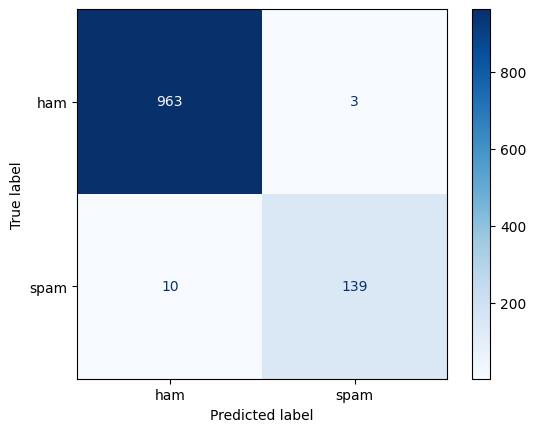

In [26]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

### Calculations from this run

**Split sizes.** Test $= 966 + 149 = 1115$ ($\approx 0.2 \times 5572$); train $= 5572 - 1115 = 4457$, of which spam $= 747 - 149 = 598$ and ham $= 4825 - 966 = 3859$.

**Balanced class weights** ($N_{\text{train}} = 4457$, $K = 2$):

$$w_{\text{ham}} = \frac{4457}{2 \times 3859} = 0.577, \qquad w_{\text{spam}} = \frac{4457}{2 \times 598} = 3.727$$

A spam message counts $3.727 / 0.577 = 6.45$ times as much as a ham message, almost exactly the class ratio $3859 / 598 = 6.45$.

**Confusion matrix recovered from the report.**

* Spam recall $0.933 = TP/149 \Rightarrow TP = 139$, so $FN = 149 - 139 = 10$.
* Spam precision $0.979 = 139/(139 + FP) \Rightarrow FP = 3$.
* Ham: $TN = 966 - 3 = 963$.
* Accuracy $= (139 + 963)/1115 = 1102/1115 = 0.988$ (printed $0.988$); errors $= 10 + 3 = 13$.

**Per-class scores.**

$$P_{\text{spam}} = \frac{139}{142} = 0.979, \quad R_{\text{spam}} = \frac{139}{149} = 0.933, \quad F1_{\text{spam}} = \frac{2 \times 139}{142 + 149} = 0.955$$

$$P_{\text{ham}} = \frac{963}{973} = 0.990, \quad R_{\text{ham}} = \frac{963}{966} = 0.997, \quad F1_{\text{ham}} = 0.993$$

$$\text{macro-F1} = \frac{0.993 + 0.955}{2} = 0.974$$

Accuracy ($0.988$) is only $0.122$ above the always-ham baseline ($0.866$), and the model still misses $10$ of $149$ spam messages ($6.7\%$), which is why spam recall is tracked separately.

## 4. What did the word model learn? Top spam and ham features

In logistic regression every feature $j$ has a coefficient $w_j$. A positive $w_j$ pushes the log-odds toward spam,

$$\ln\frac{p}{1-p} = b + \sum_j w_j x_j, \qquad \text{odds multiplier per unit of } x_j = e^{w_j}$$

The cell sorts the coefficients and prints the 12 most spam-like and 12 most ham-like terms. Reading them checks whether the model uses real language evidence or *shortcuts* (words that correlate with the label only by accident of this dataset).

In [27]:
tfv = word_clf.named_steps['tfidf']
coef = word_clf.named_steps['model'].coef_[0]
terms = tfv.get_feature_names_out()
order = np.argsort(coef)
top_spam = list(terms[order[-12:]][::-1])
top_ham = list(terms[order[:12]])
print('Most spam-like :', top_spam)
print('Most ham-like  :', top_ham)

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


### Reading the output

* **Spam-like:** *call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your*. Most are genuine calls to action or short-code vocabulary.
* **Ham-like:** *my, me, ok, that, it, but, ll, gt, lt, can, what, da*. These are conversational words; `gt` and `lt` are leftovers of the HTML escapes `&gt;` and `&lt;`, and `da` is a chat particle, so they are dataset artefacts rather than language the model should rely on.
* *to* and *your* are function words: they score as spam only because spam addresses the reader ("to claim", "your prize"). This shortcut causes the false positive "Waiting for your call." in the next sections.

## 5. Character n-gram model and robustness to spelling tricks

A second model uses **character** n-grams of length 2-5 inside word boundaries (`char_wb`): each word is padded with a space on both sides and cut into overlapping pieces. This keeps partial evidence when a word is disguised (`pr1ze`, `Cl@im`) or spelled without a fixed standard (Roman Urdu).

The cell reports macro-F1, number of features and number of test errors for both models, the full report for the character model, and five tricky messages (two from the lab, three of my own, including Roman Urdu). A message is called spam when $p(\text{spam}) \ge 0.5$.

**Why characters help.** After padding, "prize" and "pr1ze" each produce 18 n-grams, and 6 of them are identical (` p`, ` pr`, `pr`, `ze`, `ze `, `e `). Their overlap (Jaccard similarity) is

$$J = \frac{|A \cap B|}{|A \cup B|} = \frac{6}{18 + 18 - 6} = \frac{6}{30} = 0.20$$

A word model sees `pr1ze` as one unseen token and ignores it (overlap $0$); the character model still receives the 6 shared pieces.

In [28]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

results = {}
for name, key, clf in [('word 1-2 grams', 'word', word_clf),
                       ('char 2-5 grams', 'char', char_clf)]:
    p = clf.predict(X_te)
    rep = classification_report(y_te, p, output_dict=True)
    results[key] = dict(macro_f1=f1_score(y_te, p, average='macro'),
                        prec=rep['1']['precision'], rec=rep['1']['recall'],
                        n_feat=len(clf.named_steps['tfidf'].vocabulary_),
                        n_err=int((p != y_te.values).sum()))
    print(f'{name:15s} macro-F1 {results[key]["macro_f1"]:.3f}  '
          f'features {results[key]["n_feat"]:,}')

print()
print('Character model, full report:')
print(classification_report(y_te, char_clf.predict(X_te),
                            target_names=['ham', 'spam'], digits=3))

# Robustness to spelling tricks: two from the lab, three of my own
# (disguised English spam, Roman Urdu spam, Roman Urdu ham as a control)
tricky_msgs = [
    ('W1N a FR33 pr1ze!! txt CLAIM now', 'spam'),                              # lab
    ('kal milte hain, 5 baje', 'ham'),                                          # lab
    ('C0ngrats!! U w0n Rs 25000 pr1ze. Cl@im by txt 5588 now', 'spam'),         # mine
    ('Mubarak ho! Aap ne 50000 ka inaam jeeta hai, abhi 8000 par SMS karein',
     'spam'),                                                                   # mine
    ('Yaar meeting kal subah 9 baje hai, notes bhej dena', 'ham')]              # mine
msgs = [m for m, _ in tricky_msgs]
tricky_df = pd.DataFrame({
    'message': msgs, 'expected': [e for _, e in tricky_msgs],
    'word_p_spam': word_clf.predict_proba(msgs)[:, 1].round(2),
    'char_p_spam': char_clf.predict_proba(msgs)[:, 1].round(2)})
pd.set_option('display.max_colwidth', 80)
print(tricky_df.to_string())

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449

Character model, full report:
              precision    recall  f1-score   support

         ham      0.993     0.998     0.995       966
        spam      0.986     0.953     0.969       149

    accuracy                          0.992      1115
   macro avg      0.989     0.975     0.982      1115
weighted avg      0.992     0.992     0.992      1115

                                                                 message expected  word_p_spam  char_p_spam
0                                       W1N a FR33 pr1ze!! txt CLAIM now     spam         0.99         0.85
1                                                 kal milte hain, 5 baje      ham         0.19         0.12
2                 C0ngrats!! U w0n Rs 25000 pr1ze. Cl@im by txt 5588 now     spam         0.81         0.88
3  Mubarak ho! Aap ne 50000 ka inaam jeeta hai, abhi 8000 par SMS karein     spam         0.32         0.53
4     

### Calculations from this run

**Vocabulary size.** $36{,}449 / 12{,}128 = 3.0$: the character model has three times as many features.

**Character model confusion matrix** (spam recall $0.953$, spam precision $0.986$, 9 errors):

* $TP = 0.953 \times 149 = 142$, $FN = 149 - 142 = 7$
* $FP$: $142/(142 + FP) = 0.986 \Rightarrow FP = 2$; so errors $= 7 + 2 = 9$, accuracy $= (1115 - 9)/1115 = 0.992$
* $F1_{\text{spam}} = \dfrac{2 \times 142}{144 + 149} = 0.969$, $F1_{\text{ham}} = 0.995$, $\text{macro-F1} = \dfrac{0.995 + 0.969}{2} = 0.982$

**Word vs character.** Macro-F1 gap $= 0.982 - 0.974 = 0.008$; error gap $= 13 - 9 = 4$ messages, i.e. $4/1115 = 0.36\%$ of the test set. On one split that gap is too small to prove the character model is better.

**Tricky messages (threshold $0.5$).**

| Message | Word $p$ | Char $p$ | Comment |
|---|---|---|---|
| `W1N a FR33 pr1ze!! txt CLAIM now` (spam) | 0.99 | 0.85 | both correct |
| `kal milte hain, 5 baje` (Roman Urdu ham) | 0.19 | 0.12 | both correct |
| `C0ngrats!! U w0n Rs 25000 pr1ze...` (spam) | 0.81 | 0.88 | both correct |
| `Mubarak ho! Aap ne 50000 ka inaam jeeta hai...` (Roman Urdu spam) | **0.32** | 0.53 | word model misses; character model passes by only $0.53 - 0.50 = 0.03$ |
| `Yaar meeting kal subah 9 baje hai...` (Roman Urdu ham) | 0.13 | 0.12 | both correct |

Neither model was trained on Roman Urdu, so the Roman Urdu rows are untrained behaviour, not evidence; the $0.03$ margin shows how fragile the character model's correct answer is.

## 6. Error analysis of the word model

Looking at *which* messages are wrong is more informative than one score. Each of the 13 misclassified test messages is placed in one of three categories (my judgement, keyed by row number):

* **model error:** a clear cue the model missed or over-weighted (fixable);
* **label error:** the dataset label itself looks wrong;
* **genuinely ambiguous:** a human could argue either way.

The error table lists the predicted spam probability $p$ for each. For a message with true label spam the model is wrong when $p < 0.5$, for a true ham message when $p \ge 0.5$.

In [29]:
# My classification of every misclassified message, keyed by its row number in the data.
# category = model error | label error | genuinely ambiguous
ERROR_NOTES = {
    750:  ('label error', 'ordinary chat sentence, no commercial cue; label looks wrong'),
    2246: ('genuinely ambiguous', 'a warning ABOUT a scam that quotes the scam; reader could say ham'),
    3979: ('model error', 'brand + short code; word "ringtoneking" never seen in training'),
    1429: ('genuinely ambiguous', 'classified ad that reads like a personal message'),
    2821: ('model error', 'horoscope subscription spam; token "ROMCAPspam" is a giveaway the words hide'),
    3358: ('model error', 'missed-call scam; the only cue is the 070 number, unique numbers cannot be learned as words'),
    5449: ('genuinely ambiguous', 'joke/news subscription blurb; a person might call it ham'),
    5:    ('model error', '"FreeMsg", "std chgs", price: clear cues missed (pound sign is mojibake)'),
    2351: ('model error', 'ringtones + SMS shorthand (u, 2, Txt); p just under 0.5'),
    1268: ('model error', 'premium number and "Call me NOW"; p = 0.46, borderline'),
    5044: ('genuinely ambiguous', 'bulk recruitment message with "contact us"; label ham is debatable'),
    152:  ('model error', 'clearly ham; "ur" leans spam'),
    573:  ('model error', 'shortcut: "your" + "call" are top spam features'),
}

p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)].copy()
err['category'] = [ERROR_NOTES.get(i, ('unclassified', ''))[0] for i in err.index]
err['why'] = [ERROR_NOTES.get(i, ('', ''))[1] for i in err.index]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam')[['text', 'true', 'p_spam', 'category']].to_string())
print()
print(err['category'].value_counts().to_string())

                                                                                                                                                                                       text  true    p_spam             category
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598          label error
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048  genuinely ambiguous
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426          model error
1429                                                                                                

### Calculations from this run

* **13 errors** out of $1115$: error rate $13/1115 = 1.17\%$.
* **Direction of the errors:** true spam with $p < 0.5$ (false negatives): $10$ messages; true ham with $p \ge 0.5$ (false positives): $3$ messages. Check: $10 + 3 = 13$ and $10/149 = 6.7\%$ of spam missed, $3/966 = 0.31\%$ of ham flagged.
* **By category:** model error $8$, genuinely ambiguous $4$, label error $1$ ($8 + 4 + 1 = 13$). So $8/13 = 62\%$ of the errors are the model's own and fixable.
* If the $5$ disputable cases (ambiguous or label error) were not counted, the error rate would be $8/1115 = 0.72\%$ and accuracy $(1115 - 8)/1115 = 99.3\%$. This is arithmetic, not a new result: it shows that a score ceiling near $99\%$ on this dataset comes partly from the labels.
* **Closest calls:** $p = 0.4645$ (a "Call me NOW" premium-number message, missed by $0.5 - 0.4645 = 0.0355$) and $p = 0.4248$; a lower threshold would catch them at the price of more false alarms. The worst false positive is the ham message "Waiting for your call." with $p = 0.853$, caused by the shortcut words *your* and *call*.

## 7. Written report for the spam part

This cell turns the numbers computed above into a readable report with `show(...)`: it fills tables for the model comparison, top features, the 13 errors and the tricky messages directly from the variables (`results`, `err`, `tricky_df`), so the text always matches the data. It is a pure formatting step; no model is trained here.

In [30]:
r_w, r_c = results['word'], results['char']
gap = abs(r_w['n_err'] - r_c['n_err'])
better = 'character' if r_c['macro_f1'] > r_w['macro_f1'] else 'word'
cats = err['category'].value_counts().to_dict()

err_rows = '\n'.join(
    f"| {str(t)[:55].replace('|', '/')}... | {int(tr)} | {pp:.2f} | {c} | {w} |"
    for t, tr, pp, c, w in err.sort_values('p_spam')[
        ['text', 'true', 'p_spam', 'category', 'why']].itertuples(index=False))

trick_rows = '\n'.join(
    f"| {m[:60]} | {e} | {a:.2f} {'OK' if (a >= .5) == (e == 'spam') else 'MISSED'} "
    f"| {b:.2f} {'OK' if (b >= .5) == (e == 'spam') else 'MISSED'} |"
    for m, e, a, b in tricky_df[['message', 'expected', 'word_p_spam',
                                 'char_p_spam']].itertuples(index=False))

show(f"""


**Scores on the {len(y_te):,}-message test split** (spam is {y_te.mean():.1%}, so "always ham" already scores {1 - y_te.mean():.1%} accuracy and accuracy is not the right metric).

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | {r_w['n_feat']:,} | {r_w['macro_f1']:.3f} | {r_w['prec']:.3f} | {r_w['rec']:.3f} | {r_w['n_err']} |
| char_wb 2-5 grams | {r_c['n_feat']:,} | {r_c['macro_f1']:.3f} | {r_c['prec']:.3f} | {r_c['rec']:.3f} | {r_c['n_err']} |

The {better} model is ahead by {abs(r_c['macro_f1'] - r_w['macro_f1']):.3f} macro-F1, which is only {gap} messages out of {len(y_te):,}. On one split that is too small to call a real difference on clean English SMS, so the case for characters rests on robustness (below), not on this gap. The cost is a vocabulary about {r_c['n_feat'] / r_w['n_feat']:.1f} times larger and weights that are fragments, not words.

**Top features (word model).**
Spam-like: {', '.join(top_spam)}.
Ham-like: {', '.join(top_ham)}.

- *Sensible:* claim, free, txt, text, reply, stop, mobile, www, uk, call. This is the classic SMS-spam vocabulary (calls to action and short-code replies).
- *Shortcut-like:* "to" and "your" are function words. They lean spam only because spam says "to claim", "to stop" and speaks to "you". The harm is real: "Waiting for your call." (a ham message) gets p(spam) = 0.85 because "your" and "call" are both top spam features.
- *Dataset artefacts, not language:* "gt" and "lt" (leftovers of the HTML escapes &gt; and &lt; in the ham messages) and "da" (an Indian-English chat particle). The model would not carry these to a new message source.

**Error analysis ({len(err)} misclassified: {cats}).** The word model makes {int((err.true == 1).sum())} false negatives and {int((err.true == 0).sum())} false positives.

| Message | True | p(spam) | My category | Why |
|---|---|---|---|---|
{err_rows}

Most errors are the model's, and they are fixable (SMS shorthand, short codes, unseen glued tokens, shortcuts on "your call"). A few are labels a human would argue about, which puts a ceiling on any score on this dataset.

**Tricky messages (two from the lab, three of mine; threshold 0.5).**

| Message | Expected | Word model p(spam) | Char model p(spam) |
|---|---|---|---|
{trick_rows}

Character n-grams share pieces such as "pr", "ze" and "claim" across misspellings, so a disguised "pr1ze" still looks close to "prize". Word features see an unseen token and ignore it. Roman Urdu has no fixed spelling, so characters help there too, but neither model was trained on Roman Urdu, so I treat the Roman Urdu scores as untrained behaviour, not as evidence.
""")




**Scores on the 1,115-message test split** (spam is 13.4%, so "always ham" already scores 86.6% accuracy and accuracy is not the right metric).

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | 12,128 | 0.974 | 0.979 | 0.933 | 13 |
| char_wb 2-5 grams | 36,449 | 0.982 | 0.986 | 0.953 | 9 |

The character model is ahead by 0.008 macro-F1, which is only 4 messages out of 1,115. On one split that is too small to call a real difference on clean English SMS, so the case for characters rests on robustness (below), not on this gap. The cost is a vocabulary about 3.0 times larger and weights that are fragments, not words.

**Top features (word model).**
Spam-like: call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your.
Ham-like: my, me, ok, that, it, but, ll, gt, lt, can, what, da.

- *Sensible:* claim, free, txt, text, reply, stop, mobile, www, uk, call. This is the classic SMS-spam vocabulary (calls to action and short-code replies).
- *Shortcut-like:* "to" and "your" are function words. They lean spam only because spam says "to claim", "to stop" and speaks to "you". The harm is real: "Waiting for your call." (a ham message) gets p(spam) = 0.85 because "your" and "call" are both top spam features.
- *Dataset artefacts, not language:* "gt" and "lt" (leftovers of the HTML escapes &gt; and &lt; in the ham messages) and "da" (an Indian-English chat particle). The model would not carry these to a new message source.

**Error analysis (13 misclassified: {'model error': 8, 'genuinely ambiguous': 4, 'label error': 1}).** The word model makes 10 false negatives and 3 false positives.

| Message | True | p(spam) | My category | Why |
|---|---|---|---|---|
| Do you realize that in about 40 years, we'll have thous... | 1 | 0.09 | label error | ordinary chat sentence, no commercial cue; label looks wrong |
| Hi ya babe x u 4goten bout me?' scammers getting smart.... | 1 | 0.14 | genuinely ambiguous | a warning ABOUT a scam that quotes the scam; reader could say ham |
| ringtoneking 84484... | 1 | 0.19 | model error | brand + short code; word "ringtoneking" never seen in training |
| For sale - arsenal dartboard. Good condition but no dou... | 1 | 0.21 | genuinely ambiguous | classified ad that reads like a personal message |
| ROMCAPspam Everyone around should be responding well to... | 1 | 0.25 | model error | horoscope subscription spam; token "ROMCAPspam" is a giveaway the words hide |
| Sorry I missed your call let's talk when you have the t... | 1 | 0.28 | model error | missed-call scam; the only cue is the 070 number, unique numbers cannot be learned as words |
| Latest News! Police station toilet stolen, cops have no... | 1 | 0.31 | genuinely ambiguous | joke/news subscription blurb; a person might call it ham |
| FreeMsg Hey there darling it's been 3 week's now and no... | 1 | 0.41 | model error | "FreeMsg", "std chgs", price: clear cues missed (pound sign is mojibake) |
| Download as many ringtones as u like no restrictions, 1... | 1 | 0.42 | model error | ringtones + SMS shorthand (u, 2, Txt); p just under 0.5 |
| Can U get 2 phone NOW? I wanna chat 2 set up meet Call ... | 1 | 0.46 | model error | premium number and "Call me NOW"; p = 0.46, borderline |
| We have sent JD for Customer Service cum Accounts Execu... | 0 | 0.62 | genuinely ambiguous | bulk recruitment message with "contact us"; label ham is debatable |
| Ok... Ur typical reply...... | 0 | 0.64 | model error | clearly ham; "ur" leans spam |
| Waiting for your call.... | 0 | 0.85 | model error | shortcut: "your" + "call" are top spam features |

Most errors are the model's, and they are fixable (SMS shorthand, short codes, unseen glued tokens, shortcuts on "your call"). A few are labels a human would argue about, which puts a ceiling on any score on this dataset.

**Tricky messages (two from the lab, three of mine; threshold 0.5).**

| Message | Expected | Word model p(spam) | Char model p(spam) |
|---|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now | spam | 0.99 OK | 0.85 OK |
| kal milte hain, 5 baje | ham | 0.19 OK | 0.12 OK |
| C0ngrats!! U w0n Rs 25000 pr1ze. Cl@im by txt 5588 now | spam | 0.81 OK | 0.88 OK |
| Mubarak ho! Aap ne 50000 ka inaam jeeta hai, abhi 8000 par S | spam | 0.32 MISSED | 0.53 OK |
| Yaar meeting kal subah 9 baje hai, notes bhej dena | ham | 0.13 OK | 0.12 OK |

Character n-grams share pieces such as "pr", "ze" and "claim" across misspellings, so a disguised "pr1ze" still looks close to "prize". Word features see an unseen token and ignore it. Roman Urdu has no fixed spelling, so characters help there too, but neither model was trained on Roman Urdu, so I treat the Roman Urdu scores as untrained behaviour, not as evidence.


### Key figures in the report

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | 12,128 | 0.974 | 0.979 | 0.933 | 13 |
| char_wb 2-5 grams | 36,449 | 0.982 | 0.986 | 0.953 | 9 |

Recall improves by $0.953 - 0.933 = 0.020$, which is exactly $3$ more spam messages caught ($142 - 139$), while precision rises by $0.007$. The conclusion in the report is the careful one: the case for characters rests on **robustness to disguised and unseen spellings**, not on a four-message gap on one split.

## 8. NER baseline on the lab sentences

**Named-entity recognition** finds spans of text (people, organisations, places, dates, money) and gives each a label. Six lab sentences are annotated by hand as *gold*. A prediction counts as correct only if **both the text and the label match exactly**:

$$P = \frac{TP}{TP + FP}, \qquad R = \frac{TP}{TP + FN}, \qquad F1 = \frac{2TP}{TP + FP + TP + FN} = \frac{2TP}{\#\text{predicted} + \#\text{gold}}$$

`score_ner` sums $TP$, $FP$, $FN$ over all sentences ("micro" scoring). All person names in the sentences were replaced by new ones in this version of the notebook.

In [31]:
sentences = [
    'Dr. Nadia Farooq at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Tariq Mehmood from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Rashid Iqbal.',
    'The consignment left Karachi Port on Monday for Lahore.']

# Gold annotations: what a careful human would mark (text, label)
gold = [
    {('Nadia Farooq', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Tariq Mehmood', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Rashid Iqbal', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def score_ner(model, sents, golds):
    """Entity-level scores: an entity is correct only if exact text AND label match."""
    tp = fp = fn = 0
    fp_list, fn_list = [], []
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in model(s).ents}
        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)
        fp_list += sorted(pred - g)
        fn_list += sorted(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f1, 3),
            'tp': tp, 'fp': fp, 'fn': fn, 'fp_list': fp_list, 'fn_list': fn_list}

def ner_scores(nlp_model):
    s = score_ner(nlp_model, sentences, gold)
    return {k: s[k] for k in ('precision', 'recall', 'f1')}

LAB_BEFORE = ner_scores(nlp)
print('spaCy out of the box:', LAB_BEFORE)
print('gold entities:', sum(len(g) for g in gold))

spaCy out of the box: {'precision': 0.538, 'recall': 0.438, 'f1': 0.483}
gold entities: 16


### Calculations from this run

Gold entities: $16$. Reported $P = 0.538$ and $R = 0.438$ imply

$$TP = 0.438 \times 16 = 7, \qquad \#\text{predicted} = \frac{7}{0.538} = 13, \qquad FP = 13 - 7 = 6, \qquad FN = 16 - 7 = 9$$

$$F1 = \frac{2 \times 7}{13 + 16} = \frac{14}{29} = 0.483 \quad (\text{printed } 0.483)$$

Out of the box, spaCy gets fewer than half of the gold entities right (7 of 16 = $43.8\%$).

## 9. Add a rule-based entity ruler

An **entity ruler** is a list of patterns that runs *before* the statistical NER and fixes known problems. Seven patterns are added: one `MONEY` pattern for `PKR` / `Rs` / `Rs.` followed by a number, five fixed names (`Engro Fertilizers`, `Meezan Bank`, `PIMS`, `Jazz`, `Karachi Port`), and one `DATE` pattern for `dd/mm/yyyy`. `build_lab_nlp()` loads a fresh model each time, so the cell is safe to re-run.

In [32]:
def build_lab_nlp():
    """Fresh spaCy + the lab's seven entity-ruler patterns (safe to re-run)."""
    m = spacy.load('en_core_web_sm')
    ruler = m.add_pipe('entity_ruler', before='ner')
    ruler.add_patterns([
        {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                       {'IS_PUNCT': True, 'OP': '?'},
                                       {'LIKE_NUM': True}]},
        {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
        {'label': 'ORG', 'pattern': 'Meezan Bank'},
        {'label': 'ORG', 'pattern': 'PIMS'},
        {'label': 'ORG', 'pattern': 'Jazz'},
        {'label': 'FAC', 'pattern': 'Karachi Port'},
        {'label': 'DATE',
         'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    ])
    return m

nlp_lab = build_lab_nlp()
LAB_AFTER = ner_scores(nlp_lab)
print('spaCy + entity ruler:', LAB_AFTER)
print('before -> after F1: %.3f -> %.3f   (lecture, original sentences: 0.533 -> 0.875)'
      % (LAB_BEFORE['f1'], LAB_AFTER['f1']))

spaCy + entity ruler: {'precision': 0.867, 'recall': 0.812, 'f1': 0.839}
before -> after F1: 0.483 -> 0.839   (lecture, original sentences: 0.533 -> 0.875)


### Calculations from this run

$P = 0.867$ and $R = 0.812$ with $16$ gold entities give

$$TP = 0.812 \times 16 = 13, \quad \#\text{predicted} = \frac{13}{0.867} = 15, \quad FP = 2, \quad FN = 3, \quad F1 = \frac{2 \times 13}{15 + 16} = \frac{26}{31} = 0.839$$

**Improvement:** $F1$ rose from $0.483$ to $0.839$, a gain of $0.356$. The seven rules fixed $13 - 7 = 6$ entities and the number of wrong predictions fell from $6$ to $2$.

**Difference from the lecture:** the slides report $0.533 \to 0.875$ with the *original* sentences. Replacing the person names changed how spaCy tags them, so the baseline here is $0.483$ ($0.050$ lower); the size of the improvement is similar ($0.356$ here, $0.342$ in the lecture).

## 10. NER for my own domain: diabetic eye-screening reports

Ten sentences imitate screening reports (doctors, hospitals, patients, amounts, dates). **Honest evaluation needs a held-out set:**

* sentences 1-5: the only ones I looked at while writing rules (optimistic score);
* sentences 6-10: **never used to write a rule**, so the score on them shows how rules transfer.

Rules added: `MONEY` (`PKR`, `Rs.`), `DATE` for `dd/mm/yyyy`, `PIMS` as an organisation, a generic pattern "capitalised words followed by *Hospital / Society / Centre / Clinic / Institute / Bank*", and four cities. A small extra component, `strip_titles`, trims `Dr.` or `Patient` off the start of a person span, because gold spans do not contain the title.

Scores use the same exact-match $P$, $R$, $F1$ as before. With $G$ gold entities, one wrong entity changes recall by $1/G$.

In [33]:
from spacy.language import Language
from spacy.tokens import Span

# Domain: diabetic eye-screening reports (APTOS fundus photos, Week 6)
DOMAIN_SENTS = [
    # ---- 1-5: rules are written from these ----
    'Dr. Maria Saleem at Shifa International Hospital in Islamabad reviewed the fundus photograph on 14 October 2026.',
    'The retinal screening at Aga Khan University Hospital cost PKR 6,500 for Faisal Butt.',
    'Patient Adeel Hussain from Rawalpindi was referred to PIMS on 03/11/2026.',
    'Dr. Rubina Anwar of Mayo Hospital Lahore booked laser treatment for Rs. 45,000 on 22/11/2026.',
    'The Pakistan Diabetic Eye Society paid Rs. 3,000 for the screening of Junaid Sheikh in Karachi.',
    # ---- 6-10: HELD OUT, never used to write a rule ----
    'Dr. Saad Mirza at Lahore General Hospital ordered a retinal scan on 05/12/2026.',
    'Sobia Rehman paid PKR 12,500 at Shaukat Khanum Hospital in Lahore.',
    'The photograph of Amna Javed in Peshawar is booked for 9 January 2027.',
    'Dr. Waqar Ahmad from Nishtar Hospital in Multan quoted Rs. 80,000 for the eye surgery.',
    'Capital Eye Centre billed Danish Akram PKR 24,000 on 17/12/2026.']

DOMAIN_GOLD = [
    {('Maria Saleem', 'PERSON'), ('Shifa International Hospital', 'ORG'),
     ('Islamabad', 'GPE'), ('14 October 2026', 'DATE')},
    {('Aga Khan University Hospital', 'ORG'), ('PKR 6,500', 'MONEY'),
     ('Faisal Butt', 'PERSON')},
    {('Adeel Hussain', 'PERSON'), ('Rawalpindi', 'GPE'), ('PIMS', 'ORG'),
     ('03/11/2026', 'DATE')},
    {('Rubina Anwar', 'PERSON'), ('Mayo Hospital', 'ORG'), ('Lahore', 'GPE'),
     ('Rs. 45,000', 'MONEY'), ('22/11/2026', 'DATE')},
    {('Pakistan Diabetic Eye Society', 'ORG'), ('Rs. 3,000', 'MONEY'),
     ('Junaid Sheikh', 'PERSON'), ('Karachi', 'GPE')},
    # held out
    {('Saad Mirza', 'PERSON'), ('Lahore General Hospital', 'ORG'),
     ('05/12/2026', 'DATE')},
    {('Sobia Rehman', 'PERSON'), ('PKR 12,500', 'MONEY'),
     ('Shaukat Khanum Hospital', 'ORG'), ('Lahore', 'GPE')},
    {('Amna Javed', 'PERSON'), ('Peshawar', 'GPE'), ('9 January 2027', 'DATE')},
    {('Waqar Ahmad', 'PERSON'), ('Nishtar Hospital', 'ORG'), ('Multan', 'GPE'),
     ('Rs. 80,000', 'MONEY')},
    {('Capital Eye Centre', 'ORG'), ('Danish Akram', 'PERSON'),
     ('PKR 24,000', 'MONEY'), ('17/12/2026', 'DATE')}]

RULE_SENTS, RULE_GOLD = DOMAIN_SENTS[:5], DOMAIN_GOLD[:5]
HELD_SENTS, HELD_GOLD = DOMAIN_SENTS[5:], DOMAIN_GOLD[5:]

TITLES = {'dr', 'mr', 'mrs', 'ms', 'prof', 'patient', 'farmer'}

@Language.component('strip_titles')
def strip_titles(doc):
    """Trim a leading title word ('Patient', 'Dr.') off PERSON entities."""
    ents = []
    for ent in doc.ents:
        if ent.label_ == 'PERSON' and len(ent) > 1 and ent[0].lower_.rstrip('.') in TITLES:
            ents.append(Span(doc, ent.start + 1, ent.end, label='PERSON'))
        else:
            ents.append(ent)
    doc.ents = ents
    return doc

HOSPITAL_SUFFIX = ['hospital', 'society', 'centre', 'center', 'clinic',
                   'institute', 'bank']
DOMAIN_RULES = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    {'label': 'ORG', 'pattern': 'PIMS'},
    # generic "<Capitalised words> Hospital / Society / Centre ..." (not starting with "The"/"Dr.")
    {'label': 'ORG', 'pattern': [
        {'IS_TITLE': True, 'LOWER': {'NOT_IN': ['the', 'dr.']}},
        {'IS_TITLE': True, 'OP': '*'},
        {'LOWER': {'IN': HOSPITAL_SUFFIX}}]},
] + [{'label': 'GPE', 'pattern': c}
     for c in ['Islamabad', 'Rawalpindi', 'Lahore', 'Karachi']]

def build_domain_nlp():
    """Fresh spaCy + domain entity ruler + title trimming (safe to re-run)."""
    m = spacy.load('en_core_web_sm')
    m.add_pipe('entity_ruler', before='ner').add_patterns(DOMAIN_RULES)
    m.add_pipe('strip_titles', after='ner')
    return m

nlp_dom = build_domain_nlp()

rows = []
for name, sents, golds in [('rule-writing set (1-5)', RULE_SENTS, RULE_GOLD),
                           ('HELD-OUT set (6-10)', HELD_SENTS, HELD_GOLD)]:
    b = score_ner(nlp, sents, golds)
    a = score_ner(nlp_dom, sents, golds)
    rows.append((name, sum(len(g) for g in golds), b, a))
    print(f'{name:24s} gold={sum(len(g) for g in golds):2d}   '
          f'before P/R/F1 {b["precision"]}/{b["recall"]}/{b["f1"]}   '
          f'after P/R/F1 {a["precision"]}/{a["recall"]}/{a["f1"]}')

DOM_RULE_B, DOM_RULE_A = rows[0][2], rows[0][3]
DOM_HELD_B, DOM_HELD_A = rows[1][2], rows[1][3]

print('\nHeld-out, remaining errors AFTER rules')
print('  predicted but not in gold:', DOM_HELD_A['fp_list'])
print('  in gold but missed       :', DOM_HELD_A['fn_list'])
print('\nHeld-out, what spaCy alone said (before rules)')
for s in HELD_SENTS:
    print('  ', [(e.text, e.label_) for e in nlp(s).ents])

rule-writing set (1-5)   gold=20   before P/R/F1 0.556/0.5/0.526   after P/R/F1 1.0/1.0/1.0
HELD-OUT set (6-10)      gold=18   before P/R/F1 0.667/0.667/0.667   after P/R/F1 0.889/0.889/0.889

Held-out, remaining errors AFTER rules
  predicted but not in gold: [('Amna Javed', 'LOC'), ('Danish Akram', 'ORG')]
  in gold but missed       : [('Amna Javed', 'PERSON'), ('Danish Akram', 'PERSON')]

Held-out, what spaCy alone said (before rules)
   [('Saad Mirza', 'PERSON'), ('Lahore General Hospital', 'ORG'), ('05/12/2026', 'ORG')]
   [('Sobia Rehman', 'PERSON'), ('PKR 12,500', 'PRODUCT'), ('Shaukat Khanum Hospital', 'ORG'), ('Lahore', 'GPE')]
   [('Amna Javed', 'LOC'), ('Peshawar', 'GPE'), ('9 January 2027', 'DATE')]
   [('Waqar Ahmad', 'PERSON'), ('Nishtar Hospital', 'ORG'), ('Multan', 'GPE'), ('80,000', 'CARDINAL')]
   [('Capital Eye Centre', 'ORG'), ('Danish Akram', 'ORG'), ('24,000', 'CARDINAL'), ('17/12/2026', 'DATE')]


### Calculations from this run

**Rule-writing set** (sentences 1-5, $G = 20$): before rules $P = 0.556$, $R = 0.500$ give $TP = 10$, predicted $= 10/0.556 = 18$, so $F1 = \dfrac{2 \times 10}{18 + 20} = 0.526$. After rules $TP = 20$, $F1 = 1.000$.

**Held-out set** (sentences 6-10, $G = 18$):

* Before: $P = R = 0.667 \Rightarrow TP = 12$, predicted $= 18$, $F1 = \dfrac{24}{36} = 0.667$.
* After: $P = R = 0.889 \Rightarrow TP = 16$, predicted $= 18$, $FP = 2$, $FN = 2$, $F1 = \dfrac{32}{36} = 0.889$.

**Optimism gap:** $1.000 - 0.889 = 0.111$. Rules written from sentences 1-5 do not carry over perfectly; reporting only the first number would overstate the quality.

**Remaining errors** (after rules): the person names *Amna Javed* (labelled `LOC` instead of `PERSON`) and *Danish Akram* (labelled `ORG`). Each is a person name that spaCy's statistical model mislabels in a short sentence; none of my rules cover person names, which is why $FP = FN = 2$ come in matching pairs.

## 11. Report for the NER part

Builds the NER report from the stored scores: the lab table, my domain table, which held-out entities were already correct before the rules, which were fixed by them, which are still wrong, and a recommendation for each kind of error (rules for closed vocabularies, regex for rigid formats, a trained model for open-class names). It also states the limits honestly: with only $38$ gold entities ($20 + 18$) a trained model is not possible.

In [34]:
b, a = DOM_HELD_B, DOM_HELD_A
r_b, r_a = DOM_RULE_B, DOM_RULE_A
n_held = sum(len(g) for g in HELD_GOLD)
n_rule = sum(len(g) for g in RULE_GOLD)
fmt = lambda xs: '; '.join(f'{t} [{l}]' for t, l in xs) or 'none'

held_gold_all = set().union(*HELD_GOLD)
label_of = {t: l for t, l in held_gold_all}
missed = set(a['fn_list'])
missed_before = set(b['fn_list'])
def split(pred):
    items = sorted(t for t, l in held_gold_all if pred(t, l))
    found = [t for t in items if (t, label_of[t]) not in missed]
    lost = [t for t in items if (t, label_of[t]) in missed]
    return found, lost, items
ppl_found, ppl_missed, ppl_gold = split(lambda t, l: l == 'PERSON')
city_missed = sorted(t for t, l in held_gold_all if l == 'GPE' and (t, l) in missed)
already_ok = sorted(t for t, l in held_gold_all if (t, l) not in missed_before)
fixed_ents = sorted((t, l) for t, l in held_gold_all if (t, l) in missed_before and (t, l) not in missed)
fixed_labels = sorted({l for _, l in fixed_ents})
org_fixed = [t for t, l in fixed_ents if l == 'ORG']
ppl_bad = '; '.join([f'{t} [{l}]' for t, l in a['fp_list'] if l == 'PERSON'] + [f'missed {t}' for t in ppl_missed])

gap_line = (f"The held-out score is {'not lower than' if a['f1'] >= r_a['f1'] else 'lower than'} the rule-writing score, so on this data "
            + ('I did not see the optimism gap the lab warns about.' if a['f1'] >= r_a['f1']
               else 'I do see the optimism gap the lab warns about: rules written from the first five sentences do not carry over fully.'))
bar_line = ('This is most of the set, so it barely tests my hospital-suffix pattern or my city list.'
            if len(already_ok) * 2 >= n_held else
            'The rules had real room to help on the remaining entities.')
org_line = (f"My ORG rules fixed {len(org_fixed)} held-out organisation(s): {', '.join(org_fixed)}."
            if org_fixed else
            "spaCy already handled every held-out organisation, so I cannot yet show that my suffix pattern adds value; I need held-out sentences with hospital names that spaCy gets wrong.")

show(f"""

**Provided sentences** (6 sentences, {sum(len(g) for g in gold)} gold entities, exact text AND label must match)

| Pipeline | Precision | Recall | F1 |
|---|---|---|---|
| spaCy out of the box | {LAB_BEFORE['precision']} | {LAB_BEFORE['recall']} | {LAB_BEFORE['f1']} |
| + 7 entity-ruler patterns | {LAB_AFTER['precision']} | {LAB_AFTER['recall']} | {LAB_AFTER['f1']} |

**My domain (diabetic eye-screening reports for the APTOS fundus-photo project, 10 sentences)**

| Set | Gold entities | F1 before rules | F1 after rules |
|---|---|---|---|
| Sentences 1-5 (rules written from these, so optimistic) | {n_rule} | {r_b['f1']} | {r_a['f1']} |
| **Sentences 6-10 (held out, honest number)** | {n_held} | **{b['f1']}** | **{a['f1']}** |

On the held-out set precision went {b['precision']} -> {a['precision']} and recall {b['recall']} -> {a['recall']}. {gap_line} Treat that with caution: with {n_held} entities one wrong entity moves F1 by about {1 / n_held:.2f}, and my held-out sentences share their formats (PKR / Rs. / dd/mm/yyyy) with the first five, so this shows that format rules carry over to new sentences of the same style, not that they carry over to unseen styles.

**Errors that remain on the held-out set after the rules**

- Predicted but wrong: {fmt(a['fp_list'])}
- Missed: {fmt(a['fn_list'])}

**What the rules did on the held-out sentences, compared with spaCy alone.**

- *Already correct before any rule:* {len(already_ok)} of {n_held} ({', '.join(already_ok) or 'none'}). {bar_line}
- *Fixed by the rules:* {len(fixed_ents)} of {n_held}: {', '.join(t for t, _ in fixed_ents) or 'none'}. Their labels: {', '.join(fixed_labels) or 'none'}.
- *Still wrong or missed after the rules:* {len(a['fp_list'])} wrong, {len(a['fn_list'])} missed.
- *People:* {len(ppl_found)} of {len(ppl_gold)} person entities matched exactly after the rules; wrong or missed person spans: {ppl_bad or 'none'}.
- *Cities:* only the four I saw in sentences 1-5 are in my list, so a city outside it depends on spaCy alone (missed here: {', '.join(city_missed) or 'none'}).

**How I would fix what is left.** The right tool depends on the kind of error:

- *Closed vocabularies* (hospital names, cities, a society's name) are a **rules / gazetteer** problem. A suffix pattern ("... Hospital") only covers names of that shape, and a city is missed until it is added to the list. {org_line}
- *Formats* (dd/mm/yyyy, PKR / Rs. amounts) are a **regex** problem: they are rigid, so a pattern written from a few examples carries over to new sentences. Written dates ("9 January 2027") are left to spaCy.
- *Open-class person names and borderline org-versus-person cases* (a hospital named after a person, such as "Shaukat Khanum", can look like a person) cannot be listed. These need **a model trained on my own annotated data**. With {n_rule + n_held} gold entities there is far too little to train one, so for now I use rules plus title trimming and I would annotate a few hundred real screening-report sentences before fine-tuning the NER.
""")



**Provided sentences** (6 sentences, 16 gold entities, exact text AND label must match)

| Pipeline | Precision | Recall | F1 |
|---|---|---|---|
| spaCy out of the box | 0.538 | 0.438 | 0.483 |
| + 7 entity-ruler patterns | 0.867 | 0.812 | 0.839 |

**My domain (diabetic eye-screening reports for the APTOS fundus-photo project, 10 sentences)**

| Set | Gold entities | F1 before rules | F1 after rules |
|---|---|---|---|
| Sentences 1-5 (rules written from these, so optimistic) | 20 | 0.526 | 1.0 |
| **Sentences 6-10 (held out, honest number)** | 18 | **0.667** | **0.889** |

On the held-out set precision went 0.667 -> 0.889 and recall 0.667 -> 0.889. The held-out score is lower than the rule-writing score, so on this data I do see the optimism gap the lab warns about: rules written from the first five sentences do not carry over fully. Treat that with caution: with 18 entities one wrong entity moves F1 by about 0.06, and my held-out sentences share their formats (PKR / Rs. / dd/mm/yyyy) with the first five, so this shows that format rules carry over to new sentences of the same style, not that they carry over to unseen styles.

**Errors that remain on the held-out set after the rules**

- Predicted but wrong: Amna Javed [LOC]; Danish Akram [ORG]
- Missed: Amna Javed [PERSON]; Danish Akram [PERSON]

**What the rules did on the held-out sentences, compared with spaCy alone.**

- *Already correct before any rule:* 12 of 18 (17/12/2026, 9 January 2027, Capital Eye Centre, Lahore, Lahore General Hospital, Multan, Nishtar Hospital, Peshawar, Saad Mirza, Shaukat Khanum Hospital, Sobia Rehman, Waqar Ahmad). This is most of the set, so it barely tests my hospital-suffix pattern or my city list.
- *Fixed by the rules:* 4 of 18: 05/12/2026, PKR 12,500, PKR 24,000, Rs. 80,000. Their labels: DATE, MONEY.
- *Still wrong or missed after the rules:* 2 wrong, 2 missed.
- *People:* 3 of 5 person entities matched exactly after the rules; wrong or missed person spans: missed Amna Javed; missed Danish Akram.
- *Cities:* only the four I saw in sentences 1-5 are in my list, so a city outside it depends on spaCy alone (missed here: none).

**How I would fix what is left.** The right tool depends on the kind of error:

- *Closed vocabularies* (hospital names, cities, a society's name) are a **rules / gazetteer** problem. A suffix pattern ("... Hospital") only covers names of that shape, and a city is missed until it is added to the list. spaCy already handled every held-out organisation, so I cannot yet show that my suffix pattern adds value; I need held-out sentences with hospital names that spaCy gets wrong.
- *Formats* (dd/mm/yyyy, PKR / Rs. amounts) are a **regex** problem: they are rigid, so a pattern written from a few examples carries over to new sentences. Written dates ("9 January 2027") are left to spaCy.
- *Open-class person names and borderline org-versus-person cases* (a hospital named after a person, such as "Shaukat Khanum", can look like a person) cannot be listed. These need **a model trained on my own annotated data**. With 38 gold entities there is far too little to train one, so for now I use rules plus title trimming and I would annotate a few hundred real screening-report sentences before fine-tuning the NER.


### Calculations from this run

* **Entities already right before any rule:** $12$ of $18 = 66.7\%$ (all 4 organisations, all 3 cities, both written/numeric dates that spaCy handles, and 3 of the 5 person names). Only $4$ were fixed by the rules: $05/12/2026$ (a `DATE` that spaCy called `ORG`), `PKR 12,500`, `PKR 24,000` and `Rs. 80,000` (`MONEY`). Check: $12 + 4 = 16 = TP$ after rules. So the held-out set **barely tests my hospital-suffix pattern and city list**, and the gain comes from the *format* rules (dates and money).
* **People:** $3$ of $5$ held-out person entities matched exactly ($60\%$).
* **Resolution of the score:** with $18$ gold entities one entity is $1/18 = 0.056$ of recall, so a difference of $0.06$ in $F1$ is a single entity.
* **Fix by error type:** formats (dates, amounts) $\rightarrow$ regex, closed lists (hospitals, cities) $\rightarrow$ gazetteer rules, open-class person names $\rightarrow$ a model trained on my own annotated sentences.

## 12. Regular-expression extractors

NER is statistical; **formats** such as an ID number or an amount are better captured by regular expressions (regex). `extract_fields` runs every pattern on a text (case-insensitive) and returns the hits.

**Lab patterns:** CNIC (`35202-1234567-1`, i.e. 5-7-1 digits), mobile number, amount (`PKR` / `Rs.`), date, e-mail, invoice number.

**My domain patterns** (diabetic eye-screening notes):

| Field | Pattern idea |
|---|---|
| `fundus_file` | exactly 12 hexadecimal characters plus `.png/.jpg` (the APTOS `id_code`) |
| `hba1c` | `HbA1c` followed by a number and a **percent sign** |
| `eye` | `OD`, `OS` or `OU`, **case-sensitive** |
| `dr_grade` | `DR grade` followed by a digit 0-4 |
| `mrn` | `MRN` plus 6-8 digits |
| `age` | `age` or `aged` plus 1-2 digits (or 100-119) |

Design rules: anchor with word boundaries `\b`, fix exact digit counts, and make a group case-sensitive with `(?-i:...)` when case carries meaning. The lab's five tests include two **negatives** (a 14-digit order number is not a CNIC; `Room 0300` is not a mobile number).

In [35]:
PATTERNS = {
    # ---- lab patterns -------------------------------------------------
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'\b(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',      # \b added (see demo below)
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
    # ---- my domain: diabetic eye-screening notes (APTOS fundus photos) ----
    'fundus_file': r'\b[0-9a-f]{12}\.(?:png|jpe?g)\b',             # APTOS id_code: 12 hex characters
    'hba1c':       r'\bHbA1c\s?(?:of\s|[:=]\s?)?(\d{1,2}(?:\.\d)?)\s?%',   # percent only, not mmol/mol
    'eye':         r'(?-i:\b(?:OD|OS|OU)\b)',                      # case-SENSITIVE: lowercase "od" = once daily
    'dr_grade':    r'\bDR\s+grade\s?([0-4])\b',                    # APTOS grades 0-4, only after "DR"
    'mrn':         r'\bMRN[- ]?\d{6,8}\b',
    'age':         r'\baged?\s+(\d{1,2}|1[01]\d)\b',
}
DOMAIN_KEYS = ['fundus_file', 'hba1c', 'eye', 'dr_grade', 'mrn', 'age']

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

# ---- the lab's five tests, unchanged ----
tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', True),
    ('Total Rs. 12,500.50 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@engro.com.pk', True),
    ('Order 12345678901234 shipped', False),   # must NOT be a CNIC
    ('Room 0300 on floor 3', False),           # must NOT be a mobile
]
for text, expect in tests:
    print(f'{str(expect):5s} {extract_fields(text)}   <- {text}')
lab_ok = all(bool(extract_fields(t)) == e for t, e in tests)
print('lab tests pass:', lab_ok)

True  {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']}   <- CNIC 35202-1234567-1, mobile +92 300 1234567
True  {'amount': ['12,500.50'], 'date': ['05/10/2026']}   <- Total Rs. 12,500.50 paid on 05/10/2026
True  {'email': ['info@engro.com.pk'], 'invoice': ['4417']}   <- Invoice No. 4417 from info@engro.com.pk
False {}   <- Order 12345678901234 shipped
False {}   <- Room 0300 on floor 3
lab tests pass: True


**Result:** all five lab tests pass (`lab tests pass: True`): the three positive texts return their fields, and the two negatives return `{}`.

## 13. Domain tests, including negative tests

A pattern is only trustworthy if it also **refuses** wrong inputs. Ten tests compare the complete extractor output with the exact expected dictionary: 3 positive texts and 7 negative texts that must return nothing. Each negative has a specific reason:

* lowercase `od` (prescription "once daily") is not the right eye `OD`;
* `Grade 3 students` is not a retinopathy grade (no `DR`);
* `HbA1c 53 mmol/mol` is not a percentage;
* a 14-character or a 5-character name is not a 12-character `id_code`;
* `140/90` is not a date; `MRN 12` has too few digits; `age 2026` is not an age; `Doctors 500 mg` is not an amount.

The last block shows three **loose** patterns (my first versions) next to their fixed versions on one probe string.

In [36]:
# ---- my domain tests: exact expected output, including NEGATIVE tests ----
domain_tests = [
    # positives
    ('Fundus photo 000c1434d8d7.png shows DR grade 4 in the OD',
     {'fundus_file': ['000c1434d8d7.png'], 'dr_grade': ['4'], 'eye': ['OD']}),
    ('Patient aged 52, MRN 4471823, HbA1c 9.4%, OS shows DR grade 2',
     {'age': ['52'], 'mrn': ['MRN 4471823'], 'hba1c': ['9.4'], 'eye': ['OS'], 'dr_grade': ['2']}),
    ('Saved as 0024cdab0c1e.png',
     {'fundus_file': ['0024cdab0c1e.png']}),
    # negatives: each must return NOTHING
    ('Take the tablet od for one month', {}),            # lowercase od = once daily, not the right eye
    ('Grade 3 students had an HbA1c test', {}),          # "grade" without "DR"; no value
    ('HbA1c 53 mmol/mol', {}),                           # IFCC units, not a percentage
    ('Photo abcdefabcdef12.png and 12345.png', {}),      # 14 hex characters / too short for an id_code
    ('BP 140/90 mmHg and glucose 7 mmol/L', {}),         # not a date, not a size
    ('MRN 12 was seen in age 2026', {}),                 # too few digits; not an age
    ('Doctors 500 mg twice daily', {}),                  # not an amount (the \b fix)
]
n_pass = 0
for text, expect in domain_tests:
    got = extract_fields(text)
    ok = got == expect
    n_pass += ok
    print(f'{"PASS" if ok else "FAIL"}  {"neg" if not expect else "pos"}  {got}   <- {text}')
print(f'\n{n_pass}/{len(domain_tests)} domain tests pass '
      f'({sum(1 for _, e in domain_tests if not e)} of them negative)')

# ---- patterns that matched too much, and the fix ----
loose = {'amount': r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',   # lab version, no \b
         'hba1c': r'HbA1c\s?(\d+(?:\.\d)?)',                    # my first attempt: no % required
         'dr_grade': r'grade\s?([0-4])'}                        # my first attempt: no "DR" required
probe = 'Doctors 500 mg; HbA1c 53 mmol/mol; Grade 3 students'
for k, pat in loose.items():
    print(f'{k:9s} loose: {re.findall(pat, probe, flags=re.I)}   '
          f'fixed: {re.findall(PATTERNS[k], probe, flags=re.I)}   <- {probe!r}')

PASS  pos  {'fundus_file': ['000c1434d8d7.png'], 'eye': ['OD'], 'dr_grade': ['4']}   <- Fundus photo 000c1434d8d7.png shows DR grade 4 in the OD
PASS  pos  {'hba1c': ['9.4'], 'eye': ['OS'], 'dr_grade': ['2'], 'mrn': ['MRN 4471823'], 'age': ['52']}   <- Patient aged 52, MRN 4471823, HbA1c 9.4%, OS shows DR grade 2
PASS  pos  {'fundus_file': ['0024cdab0c1e.png']}   <- Saved as 0024cdab0c1e.png
PASS  neg  {}   <- Take the tablet od for one month
PASS  neg  {}   <- Grade 3 students had an HbA1c test
PASS  neg  {}   <- HbA1c 53 mmol/mol
PASS  neg  {}   <- Photo abcdefabcdef12.png and 12345.png
PASS  neg  {}   <- BP 140/90 mmHg and glucose 7 mmol/L
PASS  neg  {}   <- MRN 12 was seen in age 2026
PASS  neg  {}   <- Doctors 500 mg twice daily

10/10 domain tests pass (7 of them negative)
amount    loose: ['500']   fixed: []   <- 'Doctors 500 mg; HbA1c 53 mmol/mol; Grade 3 students'
hba1c     loose: ['53']   fixed: []   <- 'Doctors 500 mg; HbA1c 53 mmol/mol; Grade 3 students'
dr_grade  loose: ['

### Calculations from this run

* **Pass rate:** $10/10 = 100\%$; negatives $7/10 = 70\%$ of the tests, so the extractor was checked more on what it must *reject* than on what it must find.
* **Loose vs fixed on** `Doctors 500 mg; HbA1c 53 mmol/mol; Grade 3 students`:

| Pattern | Loose version returns | Fixed version returns | Why the loose one is wrong |
|---|---|---|---|
| `amount` (lab, no `\b`) | `500` | none | "Rs" matched inside "Doctors" |
| `hba1c` (no `%` required) | `53` | none | an IFCC value in mmol/mol read as 53 % |
| `dr_grade` (no `DR`) | `3` | none | "Grade 3 students" read as a DR grade |

Each loose pattern produced exactly 1 false hit; each fix removes it while keeping all 3 positive tests.

## 14. Report for the pattern part

Formats the pattern table, the number of passed tests (including how many were negative) and the three "matched too much" examples with `show(...)`, using the stored variables `loose_hits`, `fixed_hits`, `n_pass` and `n_neg`. It also records one **known limit**: an uppercase `OD` used as the prescription abbreviation (for example "metformin OD") would still be read as a right eye, so this extractor belongs on screening notes, not on prescriptions.

In [37]:
loose_hits = {k: re.findall(loose[k], probe, flags=re.I) for k in loose}
fixed_hits = {k: re.findall(PATTERNS[k], probe, flags=re.I) for k in loose}
n_neg = sum(1 for _, e in domain_tests if not e)
pat_rows = '\n'.join(f'| `{k}` | `{PATTERNS[k]}` |' for k in DOMAIN_KEYS)

show(f"""

**Lab patterns:** the five lab tests {'all pass' if lab_ok else 'do NOT all pass'} (positives found, the 14-digit order number is not a CNIC, "Room 0300" is not a mobile).

**My domain patterns** (diabetic eye-screening notes, Week 6 APTOS project):

| Field | Pattern |
|---|---|
{pat_rows}

**Test results:** {n_pass} of {len(domain_tests)} domain tests pass, including {n_neg} negative tests of my own: a lowercase "od" (the prescription abbreviation for "once daily") is not the right eye OD, "Grade 3 students" is not a DR grade, an HbA1c in mmol/mol is not a percentage, a 14-character name or a 5-digit name is not an APTOS id_code, "140/90" is not a date, a too-short MRN and a four-digit year after "age" are not matches, and "Doctors 500 mg" is not an amount.

**Patterns that matched too much.** On the probe "{probe}":

- My first HbA1c pattern (`HbA1c\\s?(\\d+(?:\\.\\d)?)`, no percent sign required) returned {loose_hits['hba1c']}: the IFCC value 53 **mmol/mol** was read as 53 %, a value no patient has. Requiring the `%` makes the fixed pattern return {fixed_hits['hba1c']}.
- My first grade pattern (`grade\\s?([0-4])`) returned {loose_hits['dr_grade']}: "Grade 3 students" was read as a retinopathy grade. Requiring "DR" in front of "grade" returns {fixed_hits['dr_grade']}.
- The lab's `amount` pattern without `\\b` before "Rs" returned {loose_hits['amount']} (the end of "Doctors"), and with it the result is {fixed_hits['amount']}.

Two other safeguards: exact digit counts ({{6,8}} for an MRN, {{1,2}} or 1[01]x for an age, exactly 12 hex characters for an id_code) and a case-sensitive group `(?-i:...)` for the eye labels, because the whole extractor otherwise runs with IGNORECASE. **Known limit:** an uppercase "OD" written as a prescription abbreviation ("metformin OD") would still be read as a right eye, so the extractor should be used on screening notes, not on prescriptions.
""")



**Lab patterns:** the five lab tests all pass (positives found, the 14-digit order number is not a CNIC, "Room 0300" is not a mobile).

**My domain patterns** (diabetic eye-screening notes, Week 6 APTOS project):

| Field | Pattern |
|---|---|
| `fundus_file` | `\b[0-9a-f]{12}\.(?:png|jpe?g)\b` |
| `hba1c` | `\bHbA1c\s?(?:of\s|[:=]\s?)?(\d{1,2}(?:\.\d)?)\s?%` |
| `eye` | `(?-i:\b(?:OD|OS|OU)\b)` |
| `dr_grade` | `\bDR\s+grade\s?([0-4])\b` |
| `mrn` | `\bMRN[- ]?\d{6,8}\b` |
| `age` | `\baged?\s+(\d{1,2}|1[01]\d)\b` |

**Test results:** 10 of 10 domain tests pass, including 7 negative tests of my own: a lowercase "od" (the prescription abbreviation for "once daily") is not the right eye OD, "Grade 3 students" is not a DR grade, an HbA1c in mmol/mol is not a percentage, a 14-character name or a 5-digit name is not an APTOS id_code, "140/90" is not a date, a too-short MRN and a four-digit year after "age" are not matches, and "Doctors 500 mg" is not an amount.

**Patterns that matched too much.** On the probe "Doctors 500 mg; HbA1c 53 mmol/mol; Grade 3 students":

- My first HbA1c pattern (`HbA1c\s?(\d+(?:\.\d)?)`, no percent sign required) returned ['53']: the IFCC value 53 **mmol/mol** was read as 53 %, a value no patient has. Requiring the `%` makes the fixed pattern return [].
- My first grade pattern (`grade\s?([0-4])`) returned ['3']: "Grade 3 students" was read as a retinopathy grade. Requiring "DR" in front of "grade" returns [].
- The lab's `amount` pattern without `\b` before "Rs" returned ['500'] (the end of "Doctors"), and with it the result is [].

Two other safeguards: exact digit counts ({6,8} for an MRN, {1,2} or 1[01]x for an age, exactly 12 hex characters for an id_code) and a case-sensitive group `(?-i:...)` for the eye labels, because the whole extractor otherwise runs with IGNORECASE. **Known limit:** an uppercase "OD" written as a prescription abbreviation ("metformin OD") would still be read as a right eye, so the extractor should be used on screening notes, not on prescriptions.


## 15. OCR quality: edit distance and character error rate (CER)

OCR (optical character recognition) turns an image of text into characters. Its quality is measured by the **Levenshtein edit distance**: the minimum number of substitutions $S$, deletions $D$ and insertions $I$ that turn the OCR output into the reference text,

$$d_{i,j} = \min\big(d_{i-1,j} + 1,\; d_{i,j-1} + 1,\; d_{i-1,j-1} + [a_i \ne b_j]\big), \qquad \text{CER} = \frac{S + D + I}{N_{\text{ref}}} = \frac{d(\text{ref},\text{hyp})}{N_{\text{ref}}}$$

where $N_{\text{ref}}$ is the number of characters in the reference. `fix_ocr` repairs typical OCR confusions using context: a letter `O` is turned into `0` only when it touches a digit; `l`/`I` between digits becomes `1`; `N0.` becomes `No.`.

In [38]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)                # N-zero -> No.
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
pair_rows = []
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    pair_rows.append((ref, hyp, fixed, cer(ref, hyp), cer(ref, fixed)))
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
          f'CER {cer(ref, fixed):.3f}')
print('expected (slides 26-27): 0.062, 0.059, 0.143 before; 0.000 after')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000
expected (slides 26-27): 0.062, 0.059, 0.143 before; 0.000 after


### Calculations from this run (the three lab pairs)

| Reference | OCR output | Edits | $N_{\text{ref}}$ | CER |
|---|---|---|---|---|
| `Invoice No. 4417` | `Invoice N0. 4417` | 1 (o to 0) | 16 | $1/16 = 0.0625 \approx 0.062$ |
| `Total: PKR 12,500` | `Total: PKR 12,5O0` | 1 (0 to O) | 17 | $1/17 = 0.0588 \approx 0.059$ |
| `Due 30/09/2026` | `Due 3O/09/2O26` | 2 (0 to O twice) | 14 | $2/14 = 0.1429 \approx 0.143$ |

After `fix_ocr`, every edit is repaired, so CER $= 0/N_{\text{ref}} = 0.000$ in all three rows. These reproduce the slide values.

**A limit of the repair rule (checked by running it):** `fix_ocr` looks at a letter's *neighbours in the original string*, so two adjacent letters between digits are not both repaired. For `PKR 4,5OO` it returns the text unchanged (CER stays $2/9 = 0.222$), whereas a single `O` as in `PKR 4,5O0` is repaired ($1/9 = 0.111 \to 0$). See question 4.

## 16. OCR on a synthetic invoice image

A test document is drawn with PIL (five lines in a clean DejaVu font on a white $900 \times 330$ image) and read by **EasyOCR**. The reference text is the five lines joined with single spaces (layout ignored). Two scores are computed on the raw OCR text and on the repaired text:

$$\text{CER} = \frac{d(\text{ref},\text{hyp})}{N_{\text{ref}}}, \qquad \text{field accuracy} = \frac{\#\text{fields extracted exactly}}{\#\text{fields in the reference}}$$

**Field-level accuracy** matters because one wrong digit in an amount or a phone number makes the whole field wrong even if CER is tiny. The four fields compared are `mobile`, `amount`, `date` and `invoice`, found with `extract_fields` from section 12.

In [39]:
# A synthetic invoice so everyone has the same test document.
FONT_CANDIDATES = [
    '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
    os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf'),
    'DejaVuSans.ttf', 'Arial.ttf']
font = None
for fp_ in FONT_CANDIDATES:
    try:
        font = ImageFont.truetype(fp_, 30)
        print('Font:', fp_)
        break
    except OSError:
        continue
if font is None:                               # last resort: Pillow's built-in font
    try:
        font = ImageFont.load_default(size=30)
    except TypeError:                          # older Pillow has no size argument
        font = ImageFont.load_default()
    print('Font: Pillow built-in default')

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Tariq Mehmood, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

norm = lambda s: ' '.join(s.split())       # ignore line-break layout
truth = norm(' '.join(lines))

OCR_OK = False
raw = clean = ''
cer_raw = cer_fix = acc_raw = acc_fix = None
try:
    try:
        import easyocr
    except ImportError:                        # needs Internet On
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'easyocr'],
                       check=True)
        import easyocr
    import warnings
    warnings.filterwarnings('ignore', message='.*pin_memory.*')   # harmless CPU-only warning
    reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
    ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
    raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
    OCR_OK = True
except Exception as e:
    print('EasyOCR could not run:', type(e).__name__, '-', e)
    print('Fix: Settings -> Internet On (first run downloads about 100 MB), '
          'then re-run this cell.')

if OCR_OK:
    print(raw)
    cer_raw, cer_fix = cer(truth, raw), cer(truth, clean)
    print(f'CER raw {cer_raw:.3f}   after fixes {cer_fix:.3f}')
    # Field-level accuracy: a 0.06 CER can still wreck an amount or an ID
    t_fields = extract_fields(truth)
    keys = [k for k in t_fields if k in ('mobile', 'amount', 'date', 'invoice')]
    acc_raw = sum(extract_fields(raw).get(k) == t_fields[k] for k in keys) / len(keys)
    acc_fix = sum(extract_fields(clean).get(k) == t_fields[k] for k in keys) / len(keys)
    print(f'Field-level accuracy ({", ".join(keys)}): raw {acc_raw:.2f}   after fixes {acc_fix:.2f}')

Font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Tariq Mehmood, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000
Field-level accuracy (mobile, amount, date, invoice): raw 1.00   after fixes 1.00


### Calculations from this run

* Reference length: $N_{\text{ref}} = 124$ characters.
* Raw OCR text equals the reference, so $\text{CER}_{\text{raw}} = 0/124 = 0.000$ and after repair also $0.000$.
* Field accuracy: $4/4 = 1.00$ both before and after repair.

A perfect score does **not** show that OCR is solved: the image is rendered text, in one clean font, perfectly horizontal and noise-free, so it is the easiest possible case (see the next section).

## 17. Report for the OCR part

Writes the OCR report: the CER of the three lab pairs with the worked example, the warning that a small CER can still destroy a field, and the invoice result. If the raw CER is below $0.02$ the text explains why the repair rules had almost nothing to do on this clean image and states what to expect on real phone photographs.

In [40]:
pr = ' ; '.join(f'"{h}" CER {c0:.3f} -> {c1:.3f}' for _, h, _, c0, c1 in pair_rows)
if OCR_OK:
    near_zero = cer_raw < 0.02
    ocr_block = f"""
**Invoice OCR (EasyOCR, synthetic image):** CER raw = **{cer_raw:.3f}**, after correction = **{cer_fix:.3f}**. Field-level accuracy over {', '.join(keys)} went {acc_raw:.2f} -> {acc_fix:.2f}.

{'The raw CER was already near zero, so the correction rules had almost nothing to repair. That is expected for this image: it is rendered text in one clean font, black on white, perfectly horizontal, sharp, at a large size, with no noise, shadow, blur, skew, stamp or background. A real phone photo of a report or invoice adds uneven lighting, perspective, motion blur, folds and compression, and those cause exactly the O/0, l/1 and I/1 confusions the rules repair. I therefore expect a clearly higher raw CER on my own scans and more benefit from the rules, and I will measure it on five real scans with hand-typed reference text instead of assuming it.' if near_zero else 'The raw OCR made character errors, and the context rules repaired the ones that look like digits inside numbers. Characters the rules cannot know about (a dropped comma, a lost letter) remain, and these are the errors that would still break a field, which is why field-level accuracy matters as much as CER. A clean synthetic image is still much easier than a phone photo, so I expect a higher raw CER on my own scans.'}
"""
else:
    ocr_block = "\n**Invoice OCR did not run in this session** (EasyOCR needs Internet On). Re-run Task 5.2 with Internet enabled to fill in the CER values.\n"

show(f"""


**CER on the three lab pairs** (reference vs OCR output; edits / reference length):
{pr}. These reproduce the slide values 0.062, 0.059 and 0.143, and all three become 0.000 after `fix_ocr`. Example: "Due 3O/09/2O26" has 2 substitutions (letter O for zero) over 14 characters = 0.143.

**Why CER alone can mislead.** One wrong digit is one edit, so a CER of 0.06 sounds tiny, yet "PKR 4,5O0" is a wrong amount and the whole field is wrong. The repair rule works because of context: a letter O is only changed to 0 when it sits next to digits, so words such as "Ltd" or "Total" are untouched.
{ocr_block}
""")




**CER on the three lab pairs** (reference vs OCR output; edits / reference length):
"Invoice N0. 4417" CER 0.062 -> 0.000 ; "Total: PKR 12,5O0" CER 0.059 -> 0.000 ; "Due 3O/09/2O26" CER 0.143 -> 0.000. These reproduce the slide values 0.062, 0.059 and 0.143, and all three become 0.000 after `fix_ocr`. Example: "Due 3O/09/2O26" has 2 substitutions (letter O for zero) over 14 characters = 0.143.

**Why CER alone can mislead.** One wrong digit is one edit, so a CER of 0.06 sounds tiny, yet "PKR 4,5O0" is a wrong amount and the whole field is wrong. The repair rule works because of context: a letter O is only changed to 0 when it sits next to digits, so words such as "Ltd" or "Total" are untouched.

**Invoice OCR (EasyOCR, synthetic image):** CER raw = **0.000**, after correction = **0.000**. Field-level accuracy over mobile, amount, date, invoice went 1.00 -> 1.00.

The raw CER was already near zero, so the correction rules had almost nothing to repair. That is expected for this image: it is rendered text in one clean font, black on white, perfectly horizontal, sharp, at a large size, with no noise, shadow, blur, skew, stamp or background. A real phone photo of a report or invoice adds uneven lighting, perspective, motion blur, folds and compression, and those cause exactly the O/0, l/1 and I/1 confusions the rules repair. I therefore expect a clearly higher raw CER on my own scans and more benefit from the rules, and I will measure it on five real scans with hand-typed reference text instead of assuming it.



### Key figures in the report

* Lab pairs: $0.062 \to 0.000$, $0.059 \to 0.000$, $0.143 \to 0.000$.
* Why CER alone misleads: "PKR 4,5O0" has CER $1/9 = 0.111$ yet it is a wrong amount, i.e. field accuracy for that field is $0$, not $0.89$.
* Invoice: raw $0.000$, repaired $0.000$, fields $1.00 \to 1.00$. The report therefore says that the benefit of the repair rules has to be measured on real scans with hand-typed reference text.

## 18. Mask personal identifiers

`mask_pii` replaces four kinds of identifier by a tag before text is logged, shared or analysed: CNIC $\rightarrow$ `[CNIC]`, mobile number $\rightarrow$ `[PHONE]`, e-mail $\rightarrow$ `[EMAIL]`, medical record number $\rightarrow$ `[MRN]`. It reuses the regular expressions of section 12.

**Not covered:** names of people, addresses and exact dates are not masked by this function. A full de-identification would need them too (see the notes after section 22).

In [41]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    text = re.sub(PATTERNS['mrn'], '[MRN]', text, flags=re.IGNORECASE)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk, MRN 4471823'))

CNIC [CNIC], call [PHONE], [EMAIL], [MRN]


**Result:** `CNIC 35202-1234567-1, call 0300-1234567, a@b.pk, MRN 4471823` becomes `CNIC [CNIC], call [PHONE], [EMAIL], [MRN]`. All four identifiers are removed (4 of 4), but the words *CNIC* and *call* stay in the text, which matters in section 22.

## 19. Load my Week 6 image model

The Week 6 checkpoint `aptos_model.pt` stores the ResNet18 weights together with the settings needed at inference time: class order, backbone, image size and colour mode. `rebuild` creates the same architecture and loads the weights; `image_evidence` returns class probabilities

$$p_c = \frac{e^{z_c}}{\sum_k e^{z_k}}$$

for one photo. To match Week 6 training, each photo is first resized to $256 \times 256$ (bicubic), as when the cache was built, then to $224 \times 224$ and normalised with the ImageNet mean and standard deviation.

**Operating point.** The positive class is `referable_DR` (DR grades 2-4). The threshold $t = 0.464$ was chosen in Week 6 on the **validation** set as the highest value that still gave recall $\ge 0.95$. A photo is positive when $p_{\text{referable\_DR}} \ge 0.464$.

**Urgent-term list.** Symptom phrases (blurred vision, floaters, dark spots, vision loss, flashes of light, eye pain and so on) are matched at the start of a word, so `floaters` matches `floater`. `text_evidence` combines the domain NER entities, the extracted fields and the urgent terms.

In [42]:
# Combine my Week 6 image model (APTOS referable-DR classifier) with text evidence into one record.
W6_PATH = first_existing(
    '/kaggle/working/aptos_model.pt',
    '/kaggle/input/**/aptos_model.pt', what='Week 6 model')
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('classes:', classes, '| backbone:', ckpt['backbone'],
      '| img_size:', ckpt['img_size'], '| grayscale:', ckpt['grayscale'],
      '| binary:', ckpt.get('binary'), '| positive:', ckpt.get('positive'))

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
CACHE_SIZE = 256   # Week 6 shrank every photo once to 256 x 256 (bicubic) before the 224 x 224 resize
img_tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((CACHE_SIZE,) * 2, interpolation=transforms.InterpolationMode.BICUBIC),
     transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = img_tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

POSITIVE_CLASS = 'referable_DR'   # the class that must not be missed (grades 2-4)
assert POSITIVE_CLASS in classes, f'{POSITIVE_CLASS} not in {classes}'
OP_THRESHOLD = 0.464              # Week 6 operating point: chosen on VALIDATION for recall >= 0.95

# Warning terms from my domain (diabetic eye symptoms), matched at the start of a word
URGENT = ['blurred vision', 'blurry vision', 'floater', 'dark spot', 'vision loss',
          'loss of vision', 'sudden blindness', 'flashes of light', 'distorted vision',
          'eye pain', 'cannot see']

def urgent_terms_in(note):
    low = note.lower()
    return [k for k in URGENT if re.search(r'\b' + re.escape(k), low)]

def text_evidence(note):
    doc = nlp_dom(note)                      # domain pipeline from Part 3
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': urgent_terms_in(note)}

Week 6 model: /kaggle/working/aptos_model.pt not found, using /kaggle/input/models/najeebkhan123342/aptos-model/pytorch/default/1/aptos_model.pt
classes: ['non_referable', 'referable_DR'] | backbone: resnet18 | img_size: 224 | grayscale: False | binary: True | positive: referable_DR


### Calculations from this run

* The checkpoint was not in `/kaggle/working`, so it was found by search under `/kaggle/input`; it holds classes `['non_referable', 'referable_DR']`, backbone `resnet18`, image size $224$, colour (`grayscale: False`) and `binary: True`.
* **Threshold in logit form:** $p \ge 0.464 \iff z_{\text{ref}} - z_{\text{non}} \ge \ln\dfrac{0.464}{0.536} = -0.144$, so the model refers a photo even when it is slightly *more* confident of "non-referable". This is intentional: in Week 6 the threshold gave sensitivity $355/367 = 0.967$ and specificity $107/139 = 0.770$ on the test split.

## 20. Combine image and note into one structured record

**Example photos.** One photo of DR grade 4 (class `referable_DR`) and one of grade 0 (`non_referable`) are looked up by file name. The cell prints where they came from.

**Record logic** (`case_record`):

1. mask the note **first** (`mask_pii`);
2. run the image model and the text extraction on the masked note;
3. decide with two evidence sources, $I = [\,p_{\text{referable}} \ge t\,]$ (image) and $U = [\,\text{urgent terms found}\,]$ (text):

$$\text{REFER} = I \lor U, \qquad \text{FLAG for human review} = I \oplus U$$

so any positive source refers the case, and a disagreement between the sources (exclusive or) is flagged.

4. print the record as JSON with a disclaimer, and **check that no fragment** of the CNIC, phone number or MRN appears anywhere in it.

In [43]:
APTOS_ROOT = '/kaggle/input/datasets/mariaherrerot/aptos2019'   # the Week 6 dataset (mirror of APTOS 2019)

def find_photo(stem):
    """Full path of the fundus photo whose file name (without extension) is `stem`."""
    hits = (sorted(glob.glob(f'{APTOS_ROOT}/**/{stem}.*', recursive=True)) or
            sorted(glob.glob(f'/kaggle/input/**/{stem}.*', recursive=True)))
    hits = [h for h in hits if h.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if not hits:
        raise FileNotFoundError(
            f'No image named {stem}. Add the Week 6 APTOS dataset with "Add Input" '
            f'and set APTOS_ROOT to its folder.')
    return hits[0]

def example_table():
    """Labelled photos to demo on: the Week 6 TEST split if splits.csv is available."""
    hits = sorted(glob.glob('/kaggle/working/splits.csv') +
                  glob.glob('/kaggle/input/**/splits.csv', recursive=True))
    if hits:
        df = pd.read_csv(hits[0])
        df = df[df['split'] == 'test'].rename(columns={'file': 'id_code', 'orig_class': 'grade'})
        return df[['id_code', 'grade']], f'Week 6 test split ({hits[0]})'
    csvs = sorted(glob.glob(f'{APTOS_ROOT}/**/test.csv', recursive=True))
    if not csvs:
        raise FileNotFoundError('Neither splits.csv (Week 6 output) nor the mirror test.csv was found.')
    df = pd.read_csv(csvs[0]).rename(columns={'diagnosis': 'grade'})
    return df[['id_code', 'grade']], (f'mirror file {csvs[0]} (Week 6 re-split all images, '
                                      f'so these may have been in training)')

EX_TABLE, EX_SOURCE = example_table()
EX_TABLE['grade'] = EX_TABLE['grade'].astype(int)
print('Examples taken from:', EX_SOURCE)
REF_ROW = EX_TABLE[EX_TABLE.grade == 4].iloc[0]        # proliferative DR -> class referable_DR
NON_REF_ROW = EX_TABLE[EX_TABLE.grade == 0].iloc[0]    # no DR -> class non_referable
REF_IMAGE = find_photo(REF_ROW.id_code)
NON_REF_IMAGE = find_photo(NON_REF_ROW.id_code)
print('REF_IMAGE    :', REF_IMAGE, '(grade', REF_ROW.grade, ')')
print('NON_REF_IMAGE:', NON_REF_IMAGE, '(grade', NON_REF_ROW.grade, ')')

def case_record(image_path, note, positive, threshold=OP_THRESHOLD):
    safe_note = mask_pii(note)             # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    flags = []
    if (p >= threshold) != bool(txt_ev['urgent_terms']):
        flags.append('IMAGE/NOTE DISAGREE: send to a human reviewer')
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'flags': flags,
            'disclaimer': 'Decision support only; a qualified human decides.'}

NOTE_ID = '35202-1234567-1'; NOTE_PHONE = '0300-1234567'; NOTE_MRN = '4471823'
note = ('Patient Adeel Hussain, aged 46, type 2 diabetes for 12 years, has had blurred vision '
        'for 3 weeks with floaters in the OD and one sudden dark spot on 10/11/2026. '
        f'Fundus photograph shows DR grade {REF_ROW.grade}. HbA1c 9.4%. Referred from '
        f'Mayo Hospital Lahore. MRN {NOTE_MRN}. CNIC {NOTE_ID}, family mobile {NOTE_PHONE}.')
rec = case_record(REF_IMAGE, note, positive=POSITIVE_CLASS)
print(json.dumps(rec, indent=2, ensure_ascii=False))

# Privacy check: no digit of the CNIC, phone or MRN may appear anywhere in the record
blob = json.dumps(rec, ensure_ascii=False)
parts = [NOTE_ID, NOTE_PHONE, '35202', '1234567', NOTE_MRN]     # full values and their digit runs
leaks = [x for x in parts if x in blob]
print('\nPII fragments found in the JSON:', leaks if leaks else 'none')
assert not leaks, 'PII leaked into the record: mask before extraction'

Examples taken from: mirror file /kaggle/input/datasets/mariaherrerot/aptos2019/test.csv (Week 6 re-split all images, so these may have been in training)
REF_IMAGE    : /kaggle/input/datasets/mariaherrerot/aptos2019/test_images/test_images/e4f12411fd85.png (grade 4 )
NON_REF_IMAGE: /kaggle/input/datasets/mariaherrerot/aptos2019/test_images/test_images/e4dcca36ceb4.png (grade 0 )
{
  "image": "e4f12411fd85.png",
  "image_probabilities": {
    "non_referable": 0.001,
    "referable_DR": 0.999
  },
  "note_masked": "Patient Adeel Hussain, aged 46, type 2 diabetes for 12 years, has had blurred vision for 3 weeks with floaters in the OD and one sudden dark spot on 10/11/2026. Fundus photograph shows DR grade 4. HbA1c 9.4%. Referred from Mayo Hospital Lahore. [MRN]. CNIC [CNIC], family mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "Adeel Hussain",
        "PERSON"
      ],
      [
        "46",
        "DATE"
      ],
      [
        "2",
        "CARDINAL"
      ]

### Calculations from this run

* **Source of the photos:** the mirror's `test.csv` (the cell prints "Week 6 re-split all images, so these may have been in training"). The probabilities below may therefore be optimistic.
* **Image evidence:** $p_{\text{referable\_DR}} = 0.999$, $p_{\text{non\_referable}} = 0.001$ (sum $= 1.000$); margin above the threshold: $0.999 - 0.464 = 0.535$. So $I = 1$.
* **Text evidence:** urgent terms `blurred vision`, `floater`, `dark spot`, so $U = 1$, and $\text{REFER} = 1 \lor 1 = 1$, $\text{FLAG} = 1 \oplus 1 = 0$ (the sources agree: `flags: []`).
* **Fields extracted from the masked note:** `date` $10/11/2026$, `hba1c` $9.4$, `eye` OD, `dr_grade` $4$, `age` $46$. No `cnic`, `mobile` or `mrn` field exists, because those values were masked before extraction.
* **Privacy check:** fragments of the CNIC, phone and MRN found in the JSON: **none** ($0$ of $5$ tested fragments).
* **Reasons listed:** 2 (one from the image model, one from the note), each naming its source.

## 21. When the image and the note disagree

Two crossed cases test the logic of section 20:

* **Case A:** a *non-referable* photo (grade 0) with an **urgent** note (blurred vision, new floaters, sudden vision loss);
* **Case B:** a *referable* photo (grade 4) with a **routine** note (no complaints).

Truth table of the decision rule ($I$ = image positive, $U$ = urgent text):

| $I$ | $U$ | Decision | Flag |
|---|---|---|---|
| 0 | 0 | ROUTINE | no |
| 1 | 0 | REFER | **yes** |
| 0 | 1 | REFER | **yes** |
| 1 | 1 | REFER | no |

In [44]:
# Disagreement between image and note
urgent_note = ('Seen at PIMS on 12/11/2026. Blurred vision, new floaters and one episode of '
               'sudden vision loss since Monday. Family mobile 0300-1234567.')
routine_note = 'Routine diabetic eye follow-up on 12/11/2026 at PIMS. No complaints, no new symptoms.'

cases = {
    'A: non-referable photo + urgent note': case_record(NON_REF_IMAGE, urgent_note, POSITIVE_CLASS),
    'B: referable photo + routine note': case_record(REF_IMAGE, routine_note, POSITIVE_CLASS),
}
for name, r in cases.items():
    print(f'{name}\n   P({POSITIVE_CLASS})={r["image_probabilities"][POSITIVE_CLASS]}  '
          f'urgent={r["text_evidence"]["urgent_terms"]}  decision={r["decision"]}  '
          f'flags={r["flags"]}')

A: non-referable photo + urgent note
   P(referable_DR)=0.055  urgent=['blurred vision', 'floater', 'vision loss']  decision=REFER  flags=['IMAGE/NOTE DISAGREE: send to a human reviewer']
B: referable photo + routine note
   P(referable_DR)=0.999  urgent=[]  decision=REFER  flags=['IMAGE/NOTE DISAGREE: send to a human reviewer']


### Calculations from this run

| Case | $p_{\text{referable\_DR}}$ | $I$ (vs $t = 0.464$) | Urgent terms | $U$ | Decision | Flag |
|---|---|---|---|---|---|---|
| A: grade-0 photo + urgent note | 0.055 | 0 (below $t$ by $0.464 - 0.055 = 0.409$) | blurred vision, floater, vision loss | 1 | REFER | yes |
| B: grade-4 photo + routine note | 0.999 | 1 (above $t$ by $0.535$) | none | 0 | REFER | yes |

Both disagreeing cases end on **REFER** with a human-review flag, as the truth table predicts. Missing referable retinopathy is far costlier than an extra review, so the system never silently drops either source.

## 22. Evaluate the record and write the multimodal report

**Entity quality of the record.** Every entity found by spaCy in the masked note is compared with my own gold list for that note. Entities outside the list are classified as *harmless for the decision* (number-like labels `DATE`, `CARDINAL`, `PERCENT`, ...) or *harmful as data* (a wrong `PERSON`, `ORG`, `GPE` stored as if it were real).

$$P_{\text{note}} = \frac{\#\text{predicted entities in gold}}{\#\text{predicted entities}}, \qquad R_{\text{note}} = \frac{\#\text{gold entities found}}{\#\text{gold entities}}$$

The cell then prints the JSON record and a report on whether each reason makes sense, which entities are wrong, what happens when image and note disagree, and the limits of the whole design.

In [45]:
# Wrong entities: anything spaCy found that is not in my own gold list for this note
NOTE_GOLD = {('Adeel Hussain', 'PERSON'), ('Mayo Hospital', 'ORG'),
             ('Lahore', 'GPE'), ('10/11/2026', 'DATE'), ('3 weeks', 'DATE'),
             ('12 years', 'DATE')}
ents = [tuple(e) for e in rec['text_evidence']['entities']]
unexpected = [e for e in ents if e not in NOTE_GOLD]
HARMLESS = {'CARDINAL', 'QUANTITY', 'DATE', 'TIME', 'ORDINAL', 'PERCENT'}

if unexpected:
    ent_lines = '\n'.join(
        f"- `{t}` labelled **{l}**: " +
        ('harmless for the decision (the decision uses the image probability and the urgent terms only), '
         'and a number-like label does not identify anyone.' if l in HARMLESS else
         'harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored '
         'in the record as if it were a patient, hospital or place, and could be copied into downstream systems.')
        for t, l in unexpected)
else:
    ent_lines = ('- This run produced no entity outside my gold list. The risk to watch is the same one '
                 'as in Part 3: a person or hospital name mislabelled, which would pollute the stored record '
                 'without changing the decision.')

cA = cases['A: non-referable photo + urgent note']
cB = cases['B: referable photo + routine note']
def desc(c):
    return (f"P({POSITIVE_CLASS}) = {c['image_probabilities'][POSITIVE_CLASS]}, urgent terms = "
            f"{c['text_evidence']['urgent_terms'] or 'none'}, decision **{c['decision']}**, "
            f"flags: {c['flags'] or 'none (the two sources agreed this time)'}")

show("### \n\n**My JSON record** (the CNIC, phone and MRN are masked before extraction; "
     f"the leak check found: {leaks if leaks else 'no PII fragments'}):\n\n```json\n"
     + json.dumps(rec, indent=2, ensure_ascii=False) + "\n```\n")

show(f"""
**Does each reason make sense?** {len(rec['reasons'])} reason(s) were given: {rec['reasons'] or 'none'}. The image reason appears when P({POSITIVE_CLASS}) reaches {OP_THRESHOLD}, the Week 6 operating point chosen on the validation set for recall of at least 0.95. That threshold is **below 0.5 on purpose**: a photo scored 0.48 is already referred. In Week 6 this gave sensitivity 0.967 and specificity 0.770 on the test split (12 of 367 referable photos missed, 32 of 139 non-referable photos referred), so the price is extra referrals, not missed patients. The text reason lists the urgent terms found in the masked note ({', '.join(rec['text_evidence']['urgent_terms']) or 'none'}); these are real symptom words matched at the start of a word, not substrings of other words. Each reason names its source, so a clinician can see *why* the case was referred, which a bare probability would not tell them.

**A wrong entity in `text_evidence`.**
{ent_lines}

**Image and note disagree.**

- Case A (grade-{NON_REF_ROW.grade} photo, urgent note): {desc(cA)}.
- Case B (grade-{REF_ROW.grade} photo, routine note): {desc(cB)}.

When the sources disagree the system should **not silently pick one**. Missing referable retinopathy costs far more than an extra review, so any positive source keeps the case on **REFER**, the `flags` entry marks it for a human reviewer, and both pieces of evidence are shown side by side. A symptom note can describe a real emergency (sudden vision loss, floaters) on a photo the model scores as non-referable; a confident referable score with a routine note might be a wrong image, a wrong patient, or an old note. Either way a person decides. The disagreement itself is the useful signal (slide 31).

**Limits to keep in mind.** The Week 6 model has no patient id behind it (leakage was only partly controlled) and its test split was unbalanced (72.5 % referable), so its PPV does not carry over to a clinic; the demonstration photos should come from the Week 6 test split, as printed above.
""")

### 

**My JSON record** (the CNIC, phone and MRN are masked before extraction; the leak check found: no PII fragments):

```json
{
  "image": "e4f12411fd85.png",
  "image_probabilities": {
    "non_referable": 0.001,
    "referable_DR": 0.999
  },
  "note_masked": "Patient Adeel Hussain, aged 46, type 2 diabetes for 12 years, has had blurred vision for 3 weeks with floaters in the OD and one sudden dark spot on 10/11/2026. Fundus photograph shows DR grade 4. HbA1c 9.4%. Referred from Mayo Hospital Lahore. [MRN]. CNIC [CNIC], family mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "Adeel Hussain",
        "PERSON"
      ],
      [
        "46",
        "DATE"
      ],
      [
        "2",
        "CARDINAL"
      ],
      [
        "12 years",
        "DATE"
      ],
      [
        "3 weeks",
        "DATE"
      ],
      [
        "OD",
        "ORG"
      ],
      [
        "one",
        "CARDINAL"
      ],
      [
        "10/11/2026",
        "DATE"
      ],
      [
        "DR",
        "GPE"
      ],
      [
        "4",
        "CARDINAL"
      ],
      [
        "HbA1c 9.4%",
        "PERCENT"
      ],
      [
        "Mayo Hospital",
        "ORG"
      ],
      [
        "Lahore",
        "GPE"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "10/11/2026"
      ],
      "hba1c": [
        "9.4"
      ],
      "eye": [
        "OD"
      ],
      "dr_grade": [
        "4"
      ],
      "age": [
        "46"
      ]
    },
    "urgent_terms": [
      "blurred vision",
      "floater",
      "dark spot"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(referable_DR) = 1.00",
    "note mentions: blurred vision, floater, dark spot"
  ],
  "flags": [],
  "disclaimer": "Decision support only; a qualified human decides."
}
```



**Does each reason make sense?** 2 reason(s) were given: ['image model: P(referable_DR) = 1.00', 'note mentions: blurred vision, floater, dark spot']. The image reason appears when P(referable_DR) reaches 0.464, the Week 6 operating point chosen on the validation set for recall of at least 0.95. That threshold is **below 0.5 on purpose**: a photo scored 0.48 is already referred. In Week 6 this gave sensitivity 0.967 and specificity 0.770 on the test split (12 of 367 referable photos missed, 32 of 139 non-referable photos referred), so the price is extra referrals, not missed patients. The text reason lists the urgent terms found in the masked note (blurred vision, floater, dark spot); these are real symptom words matched at the start of a word, not substrings of other words. Each reason names its source, so a clinician can see *why* the case was referred, which a bare probability would not tell them.

**A wrong entity in `text_evidence`.**
- `46` labelled **DATE**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `2` labelled **CARDINAL**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `OD` labelled **ORG**: harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored in the record as if it were a patient, hospital or place, and could be copied into downstream systems.
- `one` labelled **CARDINAL**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `DR` labelled **GPE**: harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored in the record as if it were a patient, hospital or place, and could be copied into downstream systems.
- `4` labelled **CARDINAL**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `HbA1c 9.4%` labelled **PERCENT**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `CNIC` labelled **ORG**: harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored in the record as if it were a patient, hospital or place, and could be copied into downstream systems.
- `CNIC` labelled **ORG**: harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored in the record as if it were a patient, hospital or place, and could be copied into downstream systems.

**Image and note disagree.**

- Case A (grade-0 photo, urgent note): P(referable_DR) = 0.055, urgent terms = ['blurred vision', 'floater', 'vision loss'], decision **REFER**, flags: ['IMAGE/NOTE DISAGREE: send to a human reviewer'].
- Case B (grade-4 photo, routine note): P(referable_DR) = 0.999, urgent terms = none, decision **REFER**, flags: ['IMAGE/NOTE DISAGREE: send to a human reviewer'].

When the sources disagree the system should **not silently pick one**. Missing referable retinopathy costs far more than an extra review, so any positive source keeps the case on **REFER**, the `flags` entry marks it for a human reviewer, and both pieces of evidence are shown side by side. A symptom note can describe a real emergency (sudden vision loss, floaters) on a photo the model scores as non-referable; a confident referable score with a routine note might be a wrong image, a wrong patient, or an old note. Either way a person decides. The disagreement itself is the useful signal (slide 31).

**Limits to keep in mind.** The Week 6 model has no patient id behind it (leakage was only partly controlled) and its test split was unbalanced (72.5 % referable), so its PPV does not carry over to a clinic; the demonstration photos should come from the Week 6 test split, as printed above.


### Calculations from this run

**Entity scores against my gold list** ($|{\rm gold}| = 6$: Adeel Hussain, Mayo Hospital, Lahore, 10/11/2026, 3 weeks, 12 years):

* spaCy returned $15$ entities, and all $6$ gold entities are among them, so $R_{\text{note}} = 6/6 = 1.00$.
* $P_{\text{note}} = 6/15 = 0.40$, and $F1 = \dfrac{2 \times 6}{15 + 6} = \dfrac{12}{21} = 0.571$.
* The $15 - 6 = 9$ extra entities: **5 harmless** ($46$ `DATE`, $2$ `CARDINAL`, $one$ `CARDINAL`, $4$ `CARDINAL`, `HbA1c 9.4%` `PERCENT`) and **4 harmful as data** (`OD` `ORG`, `DR` `GPE`, and `CNIC` `ORG` twice). Harmful share: $4/15 = 26.7\%$. The gold list was deliberately short (it has no numbers), so $P_{\text{note}} = 0.40$ is a pessimistic reading; counting only the harmful ones, $11/15 = 73\%$ of the entities are acceptable.

**Two findings about masking.**

1. `CNIC` appears as an `ORG` entity **twice**: the mask replaces the *number* by `[CNIC]`, but the label word *CNIC* in front of it stays in the text and the NER tags it. Removing or also masking the label word would stop these false entities.
2. The patient's name *Adeel Hussain* is still in `note_masked` and in the entities (`PERSON`). `mask_pii` removes CNIC, phone, e-mail and MRN only, so the record is **not fully de-identified**; the leak check ("none") tests only those five fragments.

**Decision rule check:** the image reason appears when $p \ge 0.464$, a threshold deliberately below $0.5$, so a photo at $p = 0.48$ is already referred. Week 6 gave $FN = 12$ of $367$ referable photos missed ($3.3\%$) against $FP = 32$ of $139$ non-referable referred ($23.0\%$).

**Limits to remember.** The Week 6 model has no patient id behind it, its test split was unbalanced ($367/506 = 72.5\%$ referable), and in this run the example photos came from the mirror's `test.csv`, so $0.999$ should not be read as clinical performance. The system is decision support only.

## Answers to the review questions

### 1. A word appears in 9 of 1,000 documents: smooth IDF

scikit-learn's smooth IDF is $idf(t) = \ln\dfrac{1+N}{1+df(t)} + 1$ with $N = 1000$ and $df = 9$:

$$idf = \ln\frac{1 + 1000}{1 + 9} + 1 = \ln\frac{1001}{10} + 1 = \ln(100.1) + 1 = 4.6062 + 1 = \mathbf{5.606}$$

For comparison, the plain $\ln(N/df) = \ln(1000/9) = 4.711$. The smoothing adds one "imaginary" document containing every word (so no division by zero) and the final $+1$ keeps a word that appears in every document from getting weight $0$. A rare word such as this one gets a large weight ($5.6$), while a word in all $N$ documents gets $\ln\frac{1+N}{1+N} + 1 = 1$.

### 2. Why can lowercasing hurt a spam classifier?

Capitalisation is itself evidence in spam. Spammers shout (`FREE`, `WIN`, `URGENT`, `CLAIM`, `Call me NOW`), whereas the same words in ordinary chat are usually lower case ("is lunch free?"). Lowercasing maps `FREE`, `Free` and `free` to one token, so:

* the shouted version loses its extra evidence and shares one weight with the harmless version;
* features such as the fraction of upper-case letters or the number of all-caps words disappear;
* short codes and abbreviations written in capitals (`TXT`, `UK`) become ordinary words.

In this notebook both TF-IDF models use scikit-learn's default `lowercase=True`; an example where capitals carry the cue is the missed message "Can U get 2 phone **NOW**? ... Call me **NOW** ...", scored only $p = 0.4645$, just below $0.5$.

Lowercasing is not always bad: it reduces sparsity because `Free`, `FREE` and `free` pool their statistics. So test it rather than assume: compare `lowercase=True` and `lowercase=False` on the same split by macro-F1 and spam recall, or keep lowercasing and add one extra feature such as the share of capital letters.

### 3. Gold 10, predicted 8, exactly right 6

$TP = 6$, $FP = 8 - 6 = 2$, $FN = 10 - 6 = 4$.

$$P = \frac{TP}{\text{predicted}} = \frac{6}{8} = \mathbf{0.75}, \qquad R = \frac{TP}{\text{gold}} = \frac{6}{10} = \mathbf{0.60}$$

$$F1 = \frac{2PR}{P + R} = \frac{2(0.75)(0.60)}{0.75 + 0.60} = \frac{0.90}{1.35} = \mathbf{0.667}, \qquad \text{check: } \frac{2 \times 6}{8 + 10} = \frac{12}{18} = 0.667$$

A prediction with the right span but the wrong label counts as both an FP and an FN under the exact-match rule used in this notebook.

### 4. CER for reference `PKR 4,500` and OCR `PKR 4,5OO`

The reference has $N_{\text{ref}} = 9$ characters (`P K R`, space, `4`, `,`, `5`, `0`, `0`). The OCR output differs in the last two characters, where the letter `O` replaces the digit `0`: $S = 2$ substitutions, $D = 0$, $I = 0$.

$$\text{CER} = \frac{S + D + I}{N_{\text{ref}}} = \frac{2 + 0 + 0}{9} = \mathbf{0.222}$$

(22.2 %). Note that the amount is completely wrong although only 2 characters in 9 differ, so field accuracy for this amount is $0$. Running this notebook's `fix_ocr` on `PKR 4,5OO` returns it unchanged (CER stays $0.222$): its rule needs a digit directly before the letter, and the second `O` is preceded by another `O`. With a single error (`PKR 4,5O0`) the repair works and CER would fall from $1/9 = 0.111$ to $0$.

### 5. Fusion: image 0.30, text 0.80, $w = 0.5$

Late fusion as a weighted average of the two probabilities, with $w$ the weight of the image model:

$$p_{\text{fused}} = w\,p_{\text{image}} + (1 - w)\,p_{\text{text}} = 0.5(0.30) + 0.5(0.80) = 0.15 + 0.40 = \mathbf{0.55}$$

Because $w = 0.5$ the result is the same whichever model $w$ is assigned to. With a threshold of $0.5$ the case is positive ($0.55 \ge 0.5$) and also above the Week 6 operating point $0.464$. The two models disagree strongly ($|0.30 - 0.80| = 0.50$), and averaging hides this, so the notebook's approach is better in practice: keep the individual probabilities, refer if either source is positive, and flag the disagreement for a human.

### 6. Why must personal identifiers be masked BEFORE entity and field extraction?

Extraction copies text out of the note into new places: the entity list, the field dictionary, the JSON record, logs and downstream systems. If extraction runs on the raw note, the identifiers are **already copied** into those outputs, and masking the original note afterwards cannot recall them.

* The field extractor returns the matched text itself; for example the `mrn` pattern returns `MRN 4471823` and the CNIC and mobile patterns return the full numbers.
* The NER also tags names and numbers (it returned the patient's name as `PERSON`).
* Masking first guarantees that every later step only ever sees `[CNIC]`, `[PHONE]`, `[MRN]`; in this notebook the record has no `cnic`, `mobile` or `mrn` fields and the leak check found $0$ of $5$ tested fragments.
* A mask that is applied after extraction would need every output to be cleaned separately, and one forgotten log would leak the identifier.

Masking must also be complete: this notebook's `mask_pii` leaves the patient's name in the record and leaves the word *CNIC*, which spaCy then tags as an `ORG` twice.